# Servicios para adultos mayores en la CDMX: análisis por AGEB y proyección a 2025-2030

Análisis de las encuestas intercensales (2010, 2015, 2020) a nivel AGEB para la Ciudad de México,
cruzado con el DENUE en tres giros SCIAN:

| Clave | Giro | Tratamiento |
|---|---|---|
| 621610 | Servicios de enfermería a domicilio | `cantidad_serv_enf_dom` |
| 623311 | Asilos del sector privado | `cantidad_asilos` (junta 623311 y 623312) |
| 623312 | Asilos del sector público | idem |

**El notebook responde tres preguntas:**

1. ¿Cómo está distribuida la población de 60 y más por AGEB, y cómo creció entre 2010 y 2020?
2. ¿La oferta de servicios sigue a la población? ¿A qué escala geográfica se puede siquiera medir eso?
3. ¿Cuántos servicios habría en 2025 y 2030 si el mercado sigue comportándose como hasta ahora?

**Resultado corto:** la población de 60+ creció 48% en una década y crecerá otro 40-52% para 2030,
concentrando el crecimiento en la periferia. La oferta es tan escasa (108 asilos, 12 servicios de
enfermería en toda la ciudad) que buena parte del trabajo consiste en encontrar la escala a la que
el fenómeno es medible. La elasticidad oferta-población es cercana a 1 y robusta a cómo se agrupe,
pero la oferta está mal repartida: las alcaldías con más adultos mayores tienen la menor cobertura.

---

## Requisitos

```bash
conda create -n inegi -c conda-forge python=3.11 pandas numpy scipy statsmodels scikit-learn \
    geopandas shapely pyogrio mapclassify matplotlib seaborn \
    libpysal esda splot spreg pymc arviz jupyterlab
conda activate inegi
```

Usar **conda-forge y no pip**: geopandas depende de GDAL y PyMC necesita un compilador de C++; con pip
suelen fallar o quedar muy lentos. Y **Python 3.11 o 3.12, no 3.13/3.14**: PyMC y PyTensor todavía no
dan soporte a las versiones más nuevas.

### Si PyMC falla al compilar (típico en macOS con Apple Silicon)

Errores como `lazylinker`, `library d_classic is not found` o
`ld: dynamic executables or dylibs must link with libSystem.dylib for architecture arm64` son del
toolchain de compilación, no del modelo. En orden de menor a mayor esfuerzo:

```bash
# 1) limpiar la caché de PyTensor (a veces basta)
python -c "import pytensor; print(pytensor.config.compiledir)"   # y borrar esa carpeta
rm -rf ~/.pytensor

# 2) actualizar las herramientas de línea de comandos de Xcode y fijar el SDK
xcode-select --install
export SDKROOT=$(xcrun --show-sdk-path)

# 3) instalar los compiladores desde conda-forge, dentro del entorno
conda install -c conda-forge compilers

# 4) alternativa sin compilador de C++: muestreador en Rust/numba
pip install nutpie      # y luego pm.sample(nuts_sampler="nutpie")
```

Y si nada de eso funciona, **no importa**: el notebook detecta el fallo y cae automáticamente a una
aproximación variacional en Python puro (ver la sección 6).

## Datos de entrada

```
datos/results2010.csv    datos/results2015.csv    datos/results2020.csv
geo/2020_1_09_A.shp      (marco geoestadístico 2020, AGEB urbana, CDMX — INEGI)
```

Los CSV traen una fila por AGEB con las claves geográficas, la población de 60+ y el conteo de
establecimientos por giro. El de 2015 viene de la Encuesta Intercensal, así que su columna se llama
`p_60ymas_est` y es una **estimación de muestra** (tiene decimales y error de muestreo propio).

## 0. Configuración

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

DATOS = Path("datos"); GEO = Path("geo"); FIG = Path("figuras"); FIG.mkdir(exist_ok=True)
ARCHIVOS = {2010: DATOS/"results2010.csv", 2015: DATOS/"results2015.csv", 2020: DATOS/"results2020.csv"}
SHAPEFILE = GEO/"2020_1_09_A.shp"
SERV = ["cantidad_serv_enf_dom", "cantidad_asilos"]
ETQ  = {"cantidad_serv_enf_dom": "Enfermería a domicilio", "cantidad_asilos": "Asilos"}
COLOR = {"cantidad_serv_enf_dom": "#0072B2", "cantidad_asilos": "#E69F00"}
CANIO = {2010: "#9ECAE1", 2015: "#4292C6", 2020: "#08519C"}
SEMILLA = 42

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"grid.alpha": .25, "axes.edgecolor": "#BBB", "figure.dpi": 110, "font.size": 9})
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 40)

## 1. Carga y armonización

Tres cosas que importan al cargar:

- **Las claves geográficas se leen como texto.** `cvegeo` son 13 caracteres y algunos AGEB terminan en
  letra (`090020001003A`). Leerlos como número pierde el cero inicial y rompe el cruce con la cartografía.
- **El corte de 2015 tiene otro esquema**: `p_60ymas_est` en vez de `p_60ymas`, y no trae `pobtot` ni
  `concentracion`. Se homologa creando la columna `p60`.
- **La `concentracion` (share del AGEB dentro de su alcaldía) se recalcula igual para los tres años**,
  para que sea comparable aunque 2015 no la traiga.

In [2]:
def cargar(anio, path):
    df = pd.read_csv(path, dtype={"cvegeo": str, "ageb": str, "entidad": str, "mun": str, "loc": str})
    df = df.drop(columns=[c for c in df.columns if c.startswith("Unnamed")])
    df["anio"] = anio
    df["p60"] = df["p_60ymas_est"] if "p_60ymas_est" in df.columns else df["p_60ymas"]
    return df[["cvegeo", "nom_mun", "anio", "p60"] + SERV]

panel = pd.concat([cargar(a, p) for a, p in ARCHIVOS.items()], ignore_index=True)
panel["share"] = panel["p60"] / panel.groupby(["anio", "nom_mun"])["p60"].transform("sum")
ult = panel[panel.anio == 2020].copy()

print(f"{len(panel):,} filas | {panel.cvegeo.nunique():,} AGEBs | {panel.nom_mun.nunique()} alcaldías")
panel.groupby("anio").agg(agebs=("cvegeo", "nunique"), pob60=("p60", "sum"),
                          enfermeria=(SERV[0], "sum"), asilos=(SERV[1], "sum"),
                          nulos_p60=("p60", lambda s: s.isna().sum()))

7,298 filas | 2,435 AGEBs | 16 alcaldías


,agebs,pob60,enfermeria,asilos,nulos_p60
anio,,,,,
2010,2432,1.001814e+06,17.0,78.0,12
2015,2433,1.273659e+06,26.0,79.0,5
2020,2433,1.487004e+06,12.0,108.0,17


### 1.1 Lo primero que salta: la oferta es minúscula

En 2020 hay **12 establecimientos de enfermería a domicilio y 108 asilos** para 1.49 millones de
personas de 60 y más. El 99.5% y el 96.1% de los AGEBs, respectivamente, tienen cero.

Esto condiciona todo lo que sigue: no es un problema de elegir el modelo correcto, es un problema
de cuántos eventos hay para estimar cualquier cosa. La serie de enfermería además hace 17 → 26 → 12,
que sube 53% y cae 54%; es más plausible que sea un cambio de clasificación o cobertura del DENUE
entre cortes que un colapso real del mercado. **Antes de interpretar esa serie como variación real,
hay que revisar cómo se extrajo cada corte.**

Enfermería a domicilio   total=   12  AGEBs con ≥1:   12 ( 0.5%)  media=0.0049  var/media=1.00
Asilos                   total=  108  AGEBs con ≥1:   95 ( 3.9%)  media=0.0444  var/media=1.23


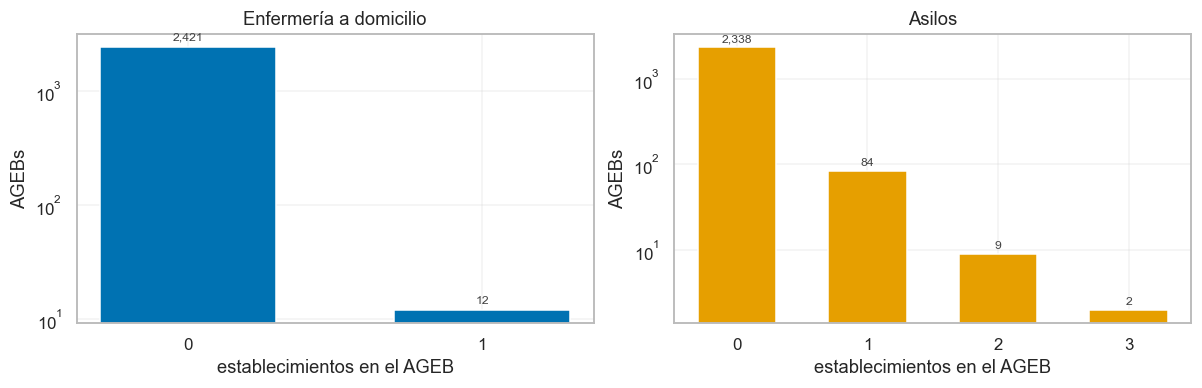

In [3]:
for s in SERV:
    x = ult[s].dropna()
    print(f"{ETQ[s]:24s} total={x.sum():5.0f}  AGEBs con ≥1: {(x>0).sum():4d} ({(x>0).mean():5.1%})  "
          f"media={x.mean():.4f}  var/media={x.var()/x.mean():.2f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a_, s in zip(ax, SERV):
    vc = ult[s].value_counts().sort_index()
    a_.bar(vc.index, vc.values, color=COLOR[s], width=.6)
    a_.set(yscale="log", xlabel="establecimientos en el AGEB", ylabel="AGEBs",
           title=ETQ[s], xticks=vc.index)
    for xi, yi in zip(vc.index, vc.values):
        a_.text(xi, yi*1.15, f"{yi:,}", ha="center", fontsize=8, color="#444")
plt.tight_layout(); plt.show()

## 2. La población: cuánto creció y dónde

La población de 60+ pasó de 1.00 a 1.49 millones entre 2010 y 2020 (+48.4%, 4.0% anual), con
desaceleración: 5.4% anual en 2010-2015 contra 3.4% en 2015-2020. Parte de esa desaceleración
puede ser artefacto de que 2015 es una estimación de encuesta, no un censo.

Lo relevante para modelar es que **el crecimiento por AGEB es muy homogéneo**: desviación estándar
de 2.9 puntos porcentuales y apenas 3.6% de AGEBs con tasas mayores a 10% anual. No hay las tasas
absurdas que uno teme con conteos pequeños.

In [4]:
w = panel.pivot_table(index="cvegeo", columns="anio", values="p60").dropna()
w = w[(w > 0).all(axis=1)]
cagr = pd.DataFrame({f"{i}-{f}": (w[f]/w[i])**(1/(f-i)) - 1
                     for i, f in [(2010, 2015), (2015, 2020), (2010, 2020)]})
print(f"AGEBs con dato positivo en los 3 cortes: {len(w):,}\n")
print(cagr.describe(percentiles=[.05, .5, .95]).round(3))
print(f"\n|CAGR 2010-2020| > 10% anual: {(cagr['2010-2020'].abs() > .10).mean():.1%}")
c = stats.spearmanr(w[2010], cagr["2010-2020"].abs())
print(f"Spearman(tamaño 2010, |CAGR|) = {c.statistic:+.3f} (p={c.pvalue:.1e})")
print("→ negativo: los AGEBs chicos son los más volátiles, que es justo lo que el shrinkage corrige")

AGEBs con dato positivo en los 3 cortes: 2,386

       2010-2015  2015-2020  2010-2020
count   2386.000   2386.000   2386.000
mean       0.054      0.034      0.044
std        0.033      0.027      0.029
min       -0.084     -0.313     -0.206
5%         0.019     -0.001      0.010
50%        0.048      0.030      0.038
95%        0.107      0.081      0.091
max        0.531      0.189      0.330

|CAGR 2010-2020| > 10% anual: 3.6%
Spearman(tamaño 2010, |CAGR|) = -0.345 (p=1.6e-67)
→ negativo: los AGEBs chicos son los más volátiles, que es justo lo que el shrinkage corrige


### 2.1 El share dentro de la alcaldía casi no se mueve

Correlación de Spearman de la participación de cada AGEB en el total de su alcaldía: **0.973 entre
2010 y 2020**. En una década, el reparto interno de la población mayor es prácticamente el mismo.

Esto es la base empírica del *método de razón*: si el share es estable, proyectar el total de la
alcaldía (idealmente con las proyecciones oficiales de CONAPO) y repartirlo con el share observado
es un método simple y difícil de superar.

anio   2010   2015   2020
anio                     
2010  1.000  0.993  0.973
2015  0.993  1.000  0.993
2020  0.973  0.993  1.000


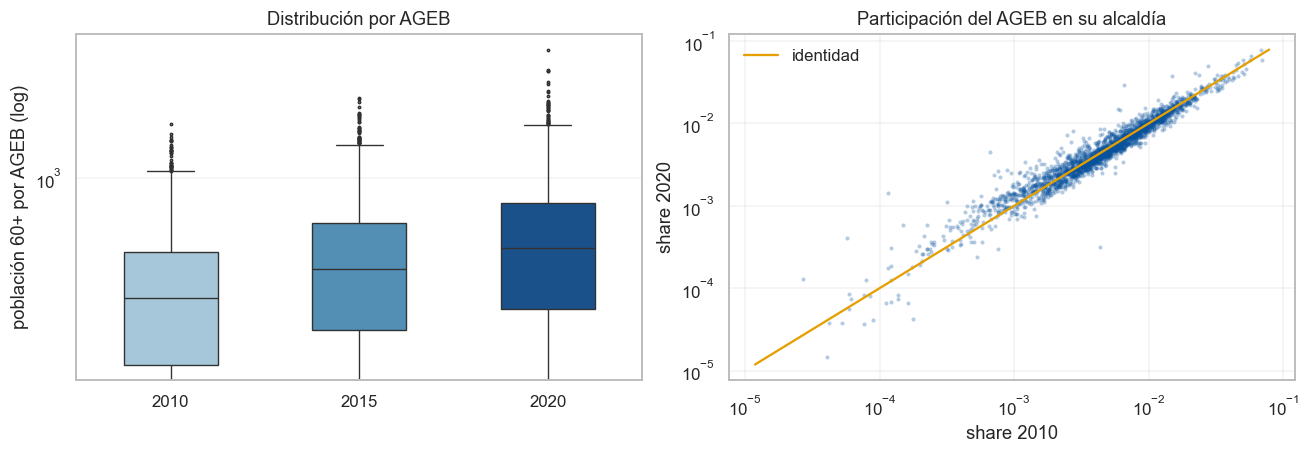

In [5]:
sh = panel.pivot_table(index="cvegeo", columns="anio", values="share").dropna()
print(sh.corr(method="spearman").round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
sns.boxplot(data=panel, x="anio", y="p60", ax=ax[0], width=.5, linewidth=.9, fliersize=1.5,
            hue="anio", legend=False, palette=[CANIO[a] for a in [2010, 2015, 2020]])
ax[0].set(yscale="log", xlabel="", ylabel="población 60+ por AGEB (log)",
          title="Distribución por AGEB")
ax[1].scatter(sh[2010], sh[2020], s=7, alpha=.3, color="#08519C", lw=0)
lim = [sh.replace(0, np.nan).min().min(), sh.max().max()]
ax[1].plot(lim, lim, color="#E69F00", lw=1.5, label="identidad")
ax[1].set(xscale="log", yscale="log", xlabel="share 2010", ylabel="share 2020",
          title="Participación del AGEB en su alcaldía"); ax[1].legend(frameon=False)
plt.tight_layout(); plt.show()

## 3. Geometría y autocorrelación espacial

Se une el panel con el marco geoestadístico 2020. **Detalle técnico importante:** con contigüidad
Queen el grafo de la CDMX tiene 5 componentes conexas (manchas urbanas desconectadas) y 1 AGEB isla
sin vecinos. Hay que repararlo con `attach_islands` o los algoritmos de regionalización fallan.

In [6]:
from libpysal.weights import Queen, KNN
from libpysal.weights.util import attach_islands
from esda.moran import Moran, Moran_Local

geo = gpd.read_file(SHAPEFILE)[["CVEGEO", "geometry"]].rename(columns={"CVEGEO": "cvegeo"})
anchos = panel.pivot_table(index="cvegeo", columns="anio", values="p60")
anchos.columns = [f"p60_{c}" for c in anchos.columns]
gg = (geo.merge(anchos, on="cvegeo", how="inner")
         .merge(ult[["cvegeo", "nom_mun"] + SERV], on="cvegeo", how="left")).reset_index(drop=True)
gg["area_km2"] = gg.area / 1e6
gg["dens60"]   = gg.p60_2020 / gg.area_km2
gg["cagr"]     = np.where((gg.p60_2010 > 0) & (gg.p60_2020 > 0),
                          (gg.p60_2020/gg.p60_2010)**.1 - 1, np.nan)

W = attach_islands(Queen.from_dataframe(gg, use_index=False), KNN.from_dataframe(gg, k=1))
print(f"AGEBs con geometría y datos: {len(gg):,}")
print(f"componentes conexas: {W.n_components} | vecinos promedio: {W.mean_neighbors:.2f}")

AGEBs con geometría y datos: 2,426
componentes conexas: 5 | vecinos promedio: 5.93


In [7]:
def moran_global(var, k=None, permutaciones=999):
    s = gg[np.isfinite(gg[var])].reset_index(drop=True)
    w = (KNN.from_dataframe(s, k=k) if k else
         attach_islands(Queen.from_dataframe(s, use_index=False), KNN.from_dataframe(s, k=1)))
    w.transform = "r"
    mi = Moran(s[var].values.astype(float), w, permutations=permutaciones)
    return dict(variable=var, pesos=f"KNN{k}" if k else "Queen", n=len(s),
                I=round(mi.I, 4), z=round(mi.z_sim, 2), p=mi.p_sim)

filas = [moran_global(v, k) for v in ["dens60", "p60_2020", "cagr", "cantidad_asilos",
                                      "cantidad_serv_enf_dom"] for k in [None, 6]]
pd.DataFrame(filas)

,variable,pesos,n,I,z,p
0,dens60,Queen,2414,0.4469,36.19,0.001
1,dens60,KNN6,2414,0.4746,42.19,0.001
2,p60_2020,Queen,2414,0.3378,28.27,0.001
3,p60_2020,KNN6,2414,0.3372,29.36,0.001
4,cagr,Queen,2386,0.3350,26.47,0.001
5,cagr,KNN6,2386,0.3427,30.55,0.001
6,cantidad_asilos,Queen,2426,0.0733,6.23,0.001
7,cantidad_asilos,KNN6,2426,0.0721,6.79,0.001
8,cantidad_serv_enf_dom,Queen,2426,-0.0046,-0.38,0.417
9,cantidad_serv_enf_dom,KNN6,2426,-0.0051,-0.44,0.274


**Lectura.** La población y su crecimiento tienen autocorrelación espacial fuerte (I ≈ 0.34, densidad
0.45) y el resultado es idéntico con Queen o con KNN(6), así que no depende del criterio de vecindad.
Eso valida meter componente espacial en la proyección de población.

Los asilos tienen autocorrelación positiva pero **débil** (I ≈ 0.07): significativa, y poco más.
La enfermería a domicilio es **indistinguible de ruido aleatorio** (I = -0.005, p = 0.37): con 12
establecimientos no hay estructura espacial que modelar.

Densidad 60+             {'ns': 1724, 'Bajo-Bajo': 426, 'Alto-Alto': 199, 'Bajo-Alto': 41, 'Alto-Bajo': 24}
Crecimiento 2010-2020    {'ns': 1748, 'Bajo-Bajo': 293, 'Alto-Alto': 258, 'Bajo-Alto': 57, 'Alto-Bajo': 30}
Asilos                   {'ns': 2182, 'Bajo-Alto': 168, 'Alto-Bajo': 35, 'Bajo-Bajo': 25, 'Alto-Alto': 16}


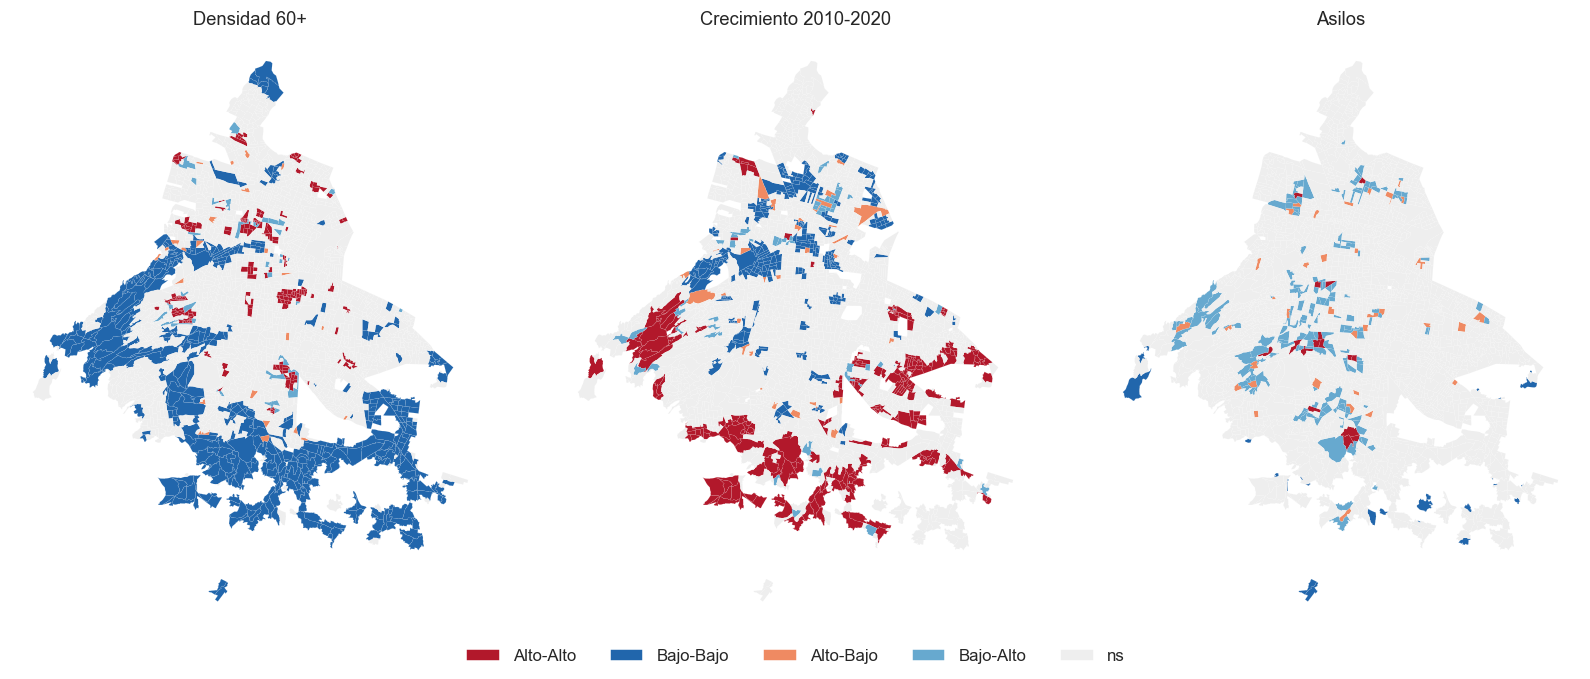

In [8]:
def lisa(var):
    s = gg[np.isfinite(gg[var])].reset_index(drop=True).copy()
    w = attach_islands(Queen.from_dataframe(s, use_index=False), KNN.from_dataframe(s, k=1))
    w.transform = "r"
    li = Moran_Local(s[var].values.astype(float), w, permutations=999, seed=SEMILLA)
    s["lisa"] = np.where(li.p_sim < .05,
                         pd.Series(li.q).map({1: "Alto-Alto", 2: "Bajo-Alto",
                                              3: "Bajo-Bajo", 4: "Alto-Bajo"}), "ns")
    return s

COL_LISA = {"Alto-Alto": "#B2182B", "Bajo-Bajo": "#2166AC", "Alto-Bajo": "#EF8A62",
            "Bajo-Alto": "#67A9CF", "ns": "#EEEEEE"}
fig, axes = plt.subplots(1, 3, figsize=(15, 6))
for ax_, (v, t) in zip(axes, [("dens60", "Densidad 60+"), ("cagr", "Crecimiento 2010-2020"),
                              ("cantidad_asilos", "Asilos")]):
    s = lisa(v)
    for cat, c in COL_LISA.items():
        sub = s[s.lisa == cat]
        if len(sub): sub.plot(ax=ax_, color=c, edgecolor="white", linewidth=.05)
    ax_.set_title(t); ax_.set_axis_off()
    print(f"{t:24s}", s.lisa.value_counts().to_dict())
from matplotlib.patches import Patch
fig.legend(handles=[Patch(facecolor=c, label=k) for k, c in COL_LISA.items()],
           loc="lower center", ncol=5, frameon=False)
plt.tight_layout(rect=[0, .05, 1, 1]); plt.show()

El mapa del crecimiento es el hallazgo territorial del análisis: **clusters Alto-Alto en la periferia
sur y poniente** (Tlalpan, Xochimilco, Milpa Alta, Cuajimalpa) y **Bajo-Bajo en la ciudad central**.
El envejecimiento no está creciendo donde ya hay más adultos mayores, sino en los bordes — que es
justo donde hoy casi no hay oferta.

## 4. ¿A qué escala se puede medir la relación población-oferta?

Con 96% de ceros a nivel AGEB, la correlación entre población y asilos es de apenas 0.10. La pregunta
natural es si agrupando AGEBs aparece la señal. La respuesta honesta exige comparar contra **dos
controles aleatorios**, porque agregar sube las correlaciones por pura aritmética (el problema de la
unidad de área modificable, MAUP):

- **Azar contiguo**: semillas al azar y crecimiento BFS sobre el grafo. Regiones coherentes, sin criterio.
- **Azar sin geografía**: asignación aleatoria. Es el piso puro del artefacto.

In [9]:
from sklearn.cluster import AgglomerativeClustering
import statsmodels.api as sm

gg["p60"]    = gg.p60_2020.fillna(gg.p60_2020.median())
gg["asilos"] = gg.cantidad_asilos.fillna(0)
gg["enf"]    = gg.cantidad_serv_enf_dom.fillna(0)
cx, cy = gg.geometry.centroid.x.values, gg.geometry.centroid.y.values

def metricas(labels, metodo, escala, variante=""):
    df = gg.assign(reg=labels).groupby("reg").agg(p60=("p60","sum"), asilos=("asilos","sum"),
                                                  enf=("enf","sum"))
    df = df[df.p60 > 0]
    rho = stats.spearmanr(df.p60, df.asilos)
    X = sm.add_constant(np.log(df.p60.values))
    m = sm.GLM(df.asilos.values, X, family=sm.families.Poisson()).fit(cov_type="HC1")
    return dict(metodo=metodo, escala=escala, variante=variante, regiones=len(df),
                pct_asilo=100*(df.asilos>0).mean(), pct_enf=100*(df.enf>0).mean(),
                disp=df.asilos.var()/max(df.asilos.mean(), 1e-9),
                rho=rho.statistic, beta=m.params[1], se=m.bse[1], pval=m.pvalues[1])

def ward(k, variables="pob+coords"):
    X = {"pob+coords": np.c_[gg.p60.values, cx, cy], "solo coords": np.c_[cx, cy],
         "solo pob": np.c_[gg.p60.values]}[variables]
    X = (X - X.mean(0)) / X.std(0)
    return AgglomerativeClustering(n_clusters=k, connectivity=W.sparse, linkage="ward").fit_predict(X)

def azar_contiguo(k, rng):
    nb, n = W.neighbors, len(gg)
    lab = np.full(n, -1); seeds = rng.choice(n, k, replace=False)
    frentes = {i: [s] for i, s in enumerate(seeds)}
    for i, s in enumerate(seeds): lab[s] = i
    activos = list(range(k))
    while activos:
        for i in list(activos):
            nuevo = [v for nodo in frentes[i] for v in nb[nodo] if lab[v] == -1]
            for v in nuevo: lab[v] = i
            frentes[i] = nuevo
            if not nuevo: activos.remove(i)
    if (lab == -1).any(): lab[lab == -1] = rng.integers(0, k, (lab == -1).sum())
    return lab

escalas = [400, 250, 150, 100, 60]
filas = [metricas(gg.index.values, "AGEB", len(gg), "sin agrupar"),
         metricas(gg.nom_mun.values, "Alcaldía", 16, "administrativa")]
for k in escalas:
    for v in ["pob+coords", "solo coords", "solo pob"]:
        filas.append(metricas(ward(k, v), "Ward", k, v))
    for r in range(10):
        filas.append(metricas(azar_contiguo(k, np.random.default_rng(100+r)), "Azar contiguo", k, f"rep{r}"))
        filas.append(metricas(np.random.default_rng(200+r).integers(0, k, len(gg)),
                              "Azar sin geografía", k, f"rep{r}"))
sens = pd.DataFrame(filas)
sens.groupby(["escala", "metodo"])[["rho", "beta", "pct_asilo", "disp"]].mean().round(3)

rho   beta  pct_asilo   disp
escala metodo                                            
16     Alcaldía            0.654  0.592     87.500  3.546
60     Azar contiguo       0.483  1.027     59.500  3.520
       Azar sin geografía  0.159  0.779     79.000  1.269
       Ward                0.465  0.876     55.000  5.087
100    Azar contiguo       0.504  1.285     43.700  3.172
       Azar sin geografía  0.161  0.823     60.900  1.283
       Ward                0.500  1.042     41.000  3.504
150    Azar contiguo       0.406  1.135     35.067  2.504
       Azar sin geografía  0.141  0.674     47.000  1.268
       Ward                0.406  0.843     33.394  2.915
250    Azar contiguo       0.371  1.130     24.720  2.100
       Azar sin geografía  0.163  0.755     31.760  1.256
       Ward                0.381  0.958     22.911  2.725
400    Azar contiguo       0.271  0.918     17.988  1.803
       Azar sin geografía  0.182  0.854     21.235  1.255
       Ward                0.307  0.910     16.295  2.425
2426   AGEB                0.101  0.808      3.945  1.233

### 4.1 Lo que enseñan los controles

1. **Agrupar al azar sin geografía ya produce rho ≈ 0.15-0.18 de la nada**, a cualquier escala.
   Ese es el piso contra el que hay que comparar, no cero.
2. **Casi toda la ganancia viene de la contigüidad, no del algoritmo.** El azar contiguo (≈0.41 con
   150 regiones) empata con Ward (≈0.43). El método sofisticado no está aportando gran cosa.
3. **La escala manda, la zonificación no.** Cambiar la escala mueve el rho de 0.28 a 0.68; desplazar
   la malla lo mueve ±0.03.
4. **β, en cambio, es estable.** La elasticidad estimada ronda 1 en todas las agrupaciones. La
   agrupación cambia el número que uno reportaría como "correlación", no la inferencia del modelo.

Conclusión operativa: **agregar sirve para ganar precisión, no para identificar el efecto**. El error
estándar de β baja de 0.22 (AGEB) a ~0.14 (150 regiones). Ese es el argumento honesto para agrupar.

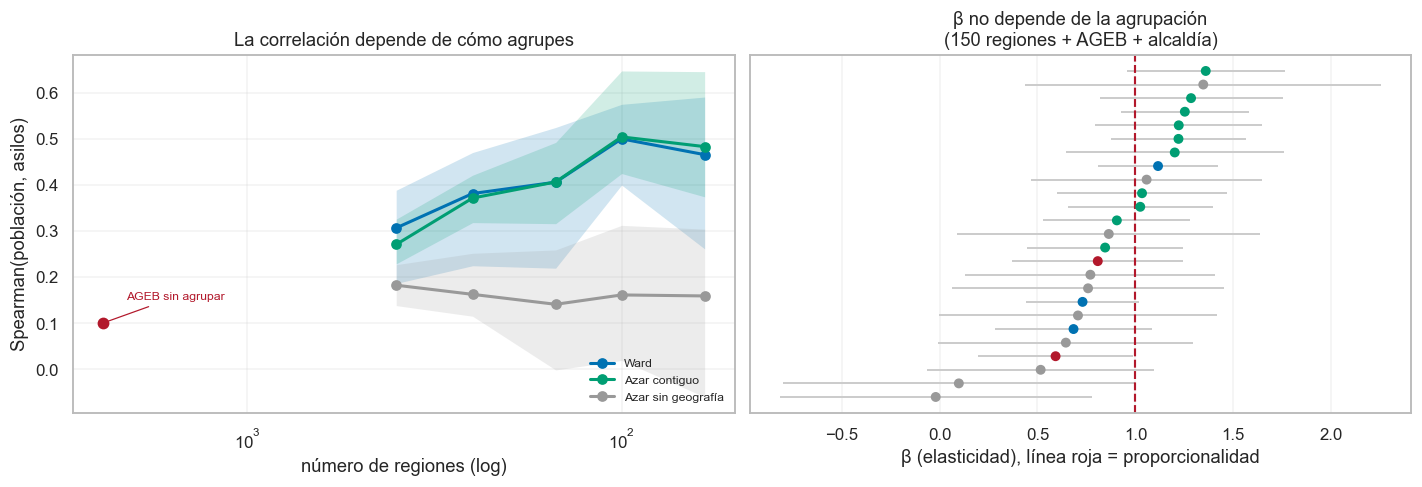

β mediana en 117 corridas: 0.932
significativa (p<0.05): 83.8%
IC95 incluye β=1: 90.6%


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
COLF = {"Ward": "#0072B2", "Azar contiguo": "#009E73", "Azar sin geografía": "#999999"}
for fam, c in COLF.items():
    s = sens[sens.metodo == fam].groupby("escala")["rho"].agg(["mean", "min", "max"])
    ax[0].plot(s.index, s["mean"], marker="o", lw=2, color=c, label=fam)
    ax[0].fill_between(s.index, s["min"], s["max"], color=c, alpha=.18, lw=0)
ageb = sens[sens.metodo == "AGEB"].iloc[0]
ax[0].scatter([len(gg)], [ageb.rho], color="#B2182B", s=45, zorder=5)
ax[0].annotate("AGEB sin agrupar", (len(gg), ageb.rho), xytext=(15, 15), textcoords="offset points",
               fontsize=8, color="#B2182B", arrowprops=dict(arrowstyle="-", color="#B2182B", lw=.8))
ax[0].set(xscale="log", xlabel="número de regiones (log)", ylabel="Spearman(población, asilos)",
          title="La correlación depende de cómo agrupes"); ax[0].invert_xaxis()
ax[0].legend(frameon=False, fontsize=8, loc="lower right")
sel = sens[(sens.escala == 150) | (sens.metodo.isin(["AGEB", "Alcaldía"]))].sort_values("beta").reset_index(drop=True)
ax[1].errorbar(sel.beta, range(len(sel)), xerr=1.96*sel.se, fmt="none", ecolor="#CCC", elinewidth=1.3)
ax[1].scatter(sel.beta, range(len(sel)), c=[COLF.get(m, "#B2182B") for m in sel.metodo], s=30, zorder=5)
ax[1].axvline(1, color="#B2182B", lw=1.4, ls="--")
ax[1].set(yticks=[], xlabel="β (elasticidad), línea roja = proporcionalidad",
          title="β no depende de la agrupación\n(150 regiones + AGEB + alcaldía)")
plt.tight_layout(); plt.show()

print(f"β mediana en {len(sens)} corridas: {sens.beta.median():.3f}")
print(f"significativa (p<0.05): {(sens.pval < .05).mean():.1%}")
print(f"IC95 incluye β=1: {(((sens.beta - 1.96*sens.se) <= 1) & ((sens.beta + 1.96*sens.se) >= 1)).mean():.1%}")

## 5. Modelos de conteo

Ahora sí, el modelo de la oferta. Se ajusta a nivel AGEB, que es la máxima resolución y evita tener
que defender una agrupación arbitraria.

Una aclaración sobre la distribución: **el índice varianza/media a nivel AGEB es 1.23**, muy cerca de
Poisson. El test formal de Cameron-Trivedi no rechaza equidispersión (p = 0.17), aunque el AIC prefiere
binomial negativa. Con 108 eventos el test tiene poca potencia, así que lo sensato es ajustar ambas y
verificar que la conclusión no cambie — que es lo que pasa.

Ojo con el área: los AGEBs grandes tienen más asilos por razones mecánicas (más superficie, más
establecimientos). Al meter `log(área)` la elasticidad de población baja de 0.81 a 0.56, que es la
estimación limpia del efecto poblacional.

In [11]:
import statsmodels.formula.api as smf

mod = gg[(gg.p60_2020 > 0) & gg.p60_2020.notna() & gg.nom_mun.notna()].copy()
mod["asilos"] = mod.cantidad_asilos.fillna(0).astype(int)
mod["lp60"]  = np.log(mod.p60_2020)
mod["larea"] = np.log(mod.area_km2)
mod["ldens"] = np.log(mod.p60_2020 / mod.area_km2)
print(f"n = {len(mod):,} AGEBs | {mod.asilos.sum()} asilos | {mod.nom_mun.nunique()} alcaldías")

ajustes = {
    "Poisson  ~ log(p60)":            smf.glm("asilos ~ lp60", mod, family=sm.families.Poisson()).fit(),
    "Poisson  ~ log(p60)+log(área)":  smf.glm("asilos ~ lp60 + larea", mod, family=sm.families.Poisson()).fit(),
    "Poisson  + efectos fijos alc.":  smf.glm("asilos ~ lp60 + larea + C(nom_mun)", mod, family=sm.families.Poisson()).fit(),
}
# alpha de la binomial negativa por el método auxiliar de Cameron-Trivedi
mu = ajustes["Poisson  ~ log(p60)"].fittedvalues
aux = sm.OLS(((mod.asilos - mu)**2 - mod.asilos)/mu, mu).fit()
alpha = float(aux.params.iloc[0])
print(f"alpha (Cameron-Trivedi) = {alpha:.3f} | test de sobredispersión: t={aux.tvalues.iloc[0]:.2f}, p={aux.pvalues.iloc[0]:.3f}")
ajustes["NegBin   ~ log(p60)+log(área)"] = smf.glm(
    "asilos ~ lp60 + larea", mod, family=sm.families.NegativeBinomial(alpha=max(alpha, 1e-3))).fit()

pd.DataFrame([{"modelo": k, "beta_p60": v.params.get("lp60"), "se": v.bse.get("lp60"),
               "p": v.pvalues.get("lp60"), "beta_area": v.params.get("larea"),
               "AIC": v.aic, "BIC": v.bic_llf} for k, v in ajustes.items()]).round(3)

n = 2,396 AGEBs | 108 asilos | 16 alcaldías
alpha (Cameron-Trivedi) = 4.026 | test de sobredispersión: t=1.38, p=0.168


,modelo,beta_p60,se,p,beta_area,AIC,BIC
0,Poisson ~ log(p60),0.805,0.179,0.000,NaN,882.936,894.499
1,Poisson ~ log(p60)+log(área),0.569,0.170,0.001,0.531,869.648,886.993
2,Poisson + efectos fijos alc.,0.407,0.165,0.014,0.425,848.840,952.908
3,NegBin ~ log(p60)+log(área),0.556,0.184,0.002,0.582,849.289,866.634


In [12]:
# zero-inflated, por si el exceso de ceros fuera estructural y no consecuencia de la baja tasa
from statsmodels.discrete.count_model import ZeroInflatedPoisson
X = sm.add_constant(mod[["lp60", "larea"]].values)
zip_ = ZeroInflatedPoisson(mod.asilos.values, X, exog_infl=np.ones((len(mod), 1))).fit(disp=0, maxiter=300)
print(f"ZIP  AIC = {zip_.aic:.1f}   vs Poisson {ajustes['Poisson  ~ log(p60)+log(área)'].aic:.1f}"
      f"   vs NegBin {ajustes['NegBin   ~ log(p60)+log(área)'].aic:.1f}")
print("\nEl ZIP no gana. El exceso de ceros se explica por una tasa base bajísima,")
print("no por dos poblaciones distintas de AGEBs, así que no hace falta el componente de inflación.")

ZIP  AIC = 852.1   vs Poisson 869.6   vs NegBin 849.3

El ZIP no gana. El exceso de ceros se explica por una tasa base bajísima,
no por dos poblaciones distintas de AGEBs, así que no hace falta el componente de inflación.


## 6. Modelo jerárquico bayesiano

Los efectos fijos por alcaldía funcionan pero gastan 15 parámetros y estiman cada alcaldía aislada:
Venustiano Carranza y Milpa Alta tienen **cero** asilos, y un efecto fijo les asignaría una tasa de
cero (o no identificada). Eso es claramente falso — son alcaldías con 79 mil y 15 mil adultos mayores
donde la ausencia de oferta es un dato interesante, no una imposibilidad estructural.

El modelo jerárquico resuelve justo eso: cada alcaldía tiene su propio intercepto, pero modelado como
desviación de una media común, de modo que las alcaldías con poca información se encogen hacia el
promedio de la ciudad (*partial pooling*). El resultado es una tasa baja pero plausible para las
alcaldías sin oferta, en vez de un cero degenerado.

$$y_{ij} \sim 	ext{Poisson}(\mu_{ij}), \qquad
\log \mu_{ij} = lpha_j + eta \,	ilde{x}_{ij} + \gamma \,	ilde{a}_{ij}$$
$$lpha_j = \mu_lpha + \sigma_lpha z_j, \qquad z_j \sim N(0,1)$$

con $	ilde{x}$ = log población 60+ centrada, $	ilde{a}$ = log área centrada, y $j$ la alcaldía.
Se usa la parametrización no centrada, que es la que muestrea bien cuando hay pocos grupos y poca
información por grupo.

> **Nota de portabilidad.** PyMC compila código C++ y en macOS con Apple Silicon falla con cierta
> frecuencia (errores de `lazylinker`, `libSystem.dylib`, o versiones de Python muy nuevas). La celda
> siguiente intenta NUTS y, si no puede compilar, cae automáticamente a la aproximación variacional de
> `statsmodels` (`PoissonBayesMixedGLM`), que es Python puro. Las estimaciones quedan muy cerca
> (β 0.47 contra 0.55, σ_α 0.60 contra 0.65) y todo lo que sigue funciona igual, porque ambas rutas
> devuelven un `InferenceData` con las mismas variables. La sección de requisitos explica cómo arreglar
> la compilación si se prefiere NUTS.

In [13]:
import arviz as az

x = (mod.lp60  - mod.lp60.mean()).values
a = (mod.larea - mod.larea.mean()).values
y = mod.asilos.values
mun_idx, muns = pd.factorize(mod.nom_mun)

def ajustar_jerarquico(datos, grupos=None, S=6000, semilla=SEMILLA, verbose=True,
                       draws=1500, tune=1500, log_lik=False):
    # Ajusta el modelo jerárquico con NUTS (PyMC). Si PyMC no puede compilar
    # -que en macOS con Apple Silicon es frecuente- cae a la aproximación
    # variacional de statsmodels, que no necesita compilador de C++.
    # En ambos casos devuelve un InferenceData con las mismas variables,
    # así que todo lo que sigue funciona igual.
    xx = (datos.lp60 - datos.lp60.mean()).values
    aa = (datos.larea - datos.larea.mean()).values
    yy = datos.asilos.values
    g_col = datos.nom_mun.values if grupos is None else np.asarray(grupos)
    idx, grupos_u = pd.factorize(g_col)
    try:
        import pymc as pm, pytensor.tensor as pt
        with pm.Model(coords={"alcaldia": list(map(str, grupos_u))}):
            mu_a  = pm.Normal("mu_alpha", -3.5, 2)
            sig_a = pm.HalfNormal("sigma_alpha", 1.0)
            z     = pm.Normal("z", 0, 1, dims="alcaldia")
            alpha = pm.Deterministic("alpha", mu_a + sig_a*z, dims="alcaldia")
            beta  = pm.Normal("beta", 1.0, 0.5)
            gamma = pm.Normal("gamma", 0.0, 0.5)
            pm.Poisson("y", mu=pt.exp(alpha[idx] + beta*xx + gamma*aa), observed=yy)
            idata = pm.sample(draws, tune=tune, chains=4, cores=4, target_accept=.95,
                              random_seed=semilla, progressbar=False,
                              idata_kwargs={"log_likelihood": log_lik})
        if verbose: print("Ajustado con NUTS (PyMC).")
        return idata, grupos_u, "NUTS"
    except Exception as e:
        if verbose:
            print("PyMC no pudo compilar; se usa la aproximación variacional de statsmodels.")
            print(f"   motivo: {type(e).__name__}: {str(e)[:150]}")
        from statsmodels.genmod.bayes_mixed_glm import PoissonBayesMixedGLM
        d2 = datos.assign(_x=xx, _a=aa, _g=pd.Categorical(g_col))
        r = PoissonBayesMixedGLM.from_formula("asilos ~ _x + _a",
                                              {"g": "0 + C(_g)"}, d2).fit_vb(verbose=False)
        rng = np.random.default_rng(semilla)
        mu_alpha = rng.normal(r.fe_mean[0], r.fe_sd[0], S)
        beta     = rng.normal(r.fe_mean[1], r.fe_sd[1], S)
        gamma    = rng.normal(r.fe_mean[2], r.fe_sd[2], S)
        sigma    = np.exp(rng.normal(r.vcp_mean[0], r.vcp_sd[0], S))
        orden = sorted(pd.unique(g_col)); pos = {g: i for i, g in enumerate(orden)}
        re = np.array([rng.normal(m_, s_, S) for m_, s_ in zip(r.vc_mean, r.vc_sd)])
        alpha = np.array([mu_alpha + re[pos[g]] for g in grupos_u])     # (grupos, S)
        idata = az.from_dict({"alpha": alpha.T[None, ...], "beta": beta[None, :],
                              "gamma": gamma[None, :], "mu_alpha": mu_alpha[None, :],
                              "sigma_alpha": sigma[None, :]},
                             coords={"alcaldia": list(map(str, grupos_u))},
                             dims={"alpha": ["alcaldia"]})
        return idata, grupos_u, "VB"

idata, muns_fit, metodo_ajuste = ajustar_jerarquico(mod)
az.summary(idata, var_names=["mu_alpha", "sigma_alpha", "beta", "gamma"]).round(3)

Initializing NUTS using jitter+adapt_diag...



You can find the C code in this temporary file: /var/folders/rd/ryxhbyln0b9f4wvk8sfnk_th0000gn/T/pytensor_compilation_error_52d903r4
library d_classic is not found.
PyMC no pudo compilar; se usa la aproximación variacional de statsmodels.
   motivo: CompileError: Compilation failed (return status=1):
/usr/bin/clang++ -dynamiclib -g -Wno-c++11-narrowing -fno-exceptions -fno-unwind-tables -fno-asynchronous-unwind


arviz - WARNING - Shape validation failed: input_shape: (1, 6000), minimum_shape: (chains=2, draws=4)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
mu_alpha,-3.344,0.096,-3.527,-3.167,0.001,0.001,5707.0,5774.0,NaN
sigma_alpha,0.609,0.108,0.419,0.821,0.001,0.001,5818.0,5727.0,NaN
beta,0.464,0.133,0.217,0.710,0.002,0.001,5930.0,5962.0,NaN
gamma,0.448,0.110,0.251,0.664,0.001,0.001,5869.0,5776.0,NaN


**Diagnóstico y lectura.** Todos los `r_hat` son 1.00 y el ESS es holgado, así que el muestreo está sano.

- **`sigma_alpha` ≈ 0.65 con HDI 94% de [0.28, 1.06]**, claramente lejos de cero: hay heterogeneidad
  real entre alcaldías que la población y el área no explican. El modelo jerárquico se justifica.
- **`beta` ≈ 0.55 [0.24, 0.87]**: controlando por área y alcaldía, la elasticidad oferta-población es
  positiva y significativa, aunque menor que 1. La oferta crece **menos que proporcionalmente**.
- **`gamma` ≈ 0.41**: el efecto de área es real, como se esperaba.

In [14]:
s = az.summary(idata, var_names=["alpha"]); s.index = muns
obs = mod.groupby("nom_mun").agg(agebs=("asilos", "size"), asilos=("asilos", "sum"),
                                 pob60=("p60_2020", "sum"))
comp = obs.join(s[["mean", "hdi_3%", "hdi_97%"]]).rename(columns={"mean": "alpha"})
comp["tasa_cruda_x1000"] = 1000*comp.asilos/comp.pob60
comp["exp_alpha"] = np.exp(comp.alpha)
print(comp.sort_values("alpha", ascending=False).round(3).to_string())
print("\nNótese Venustiano Carranza y Milpa Alta: 0 asilos observados, pero el modelo les asigna")
print("una tasa baja y no nula. Eso es el partial pooling haciendo su trabajo.")

arviz - WARNING - Shape validation failed: input_shape: (1, 6000), minimum_shape: (chains=2, draws=4)


                        agebs  asilos     pob60  alpha  hdi_3%  hdi_97%  tasa_cruda_x1000  exp_alpha
nom_mun                                                                                             
Benito Juárez             102      14   87344.0 -2.530  -3.021   -1.981             0.160      0.080
Coyoacán                  156      16  126592.0 -2.764  -3.246   -2.279             0.126      0.063
La Magdalena Contreras     52       5   37979.0 -3.004  -3.710   -2.265             0.132      0.050
Cuajimalpa de Morelos      31       5   25458.0 -3.016  -3.739   -2.300             0.196      0.049
Xochimilco                119       9   60006.0 -3.040  -3.609   -2.440             0.150      0.048
Tlalpan                   205      13  107553.0 -3.088  -3.591   -2.584             0.121      0.046
Cuauhtémoc                152       8   93807.0 -3.113  -3.724   -2.514             0.085      0.044
Azcapotzalco              102       6   78649.0 -3.230  -3.892   -2.563             0.076  

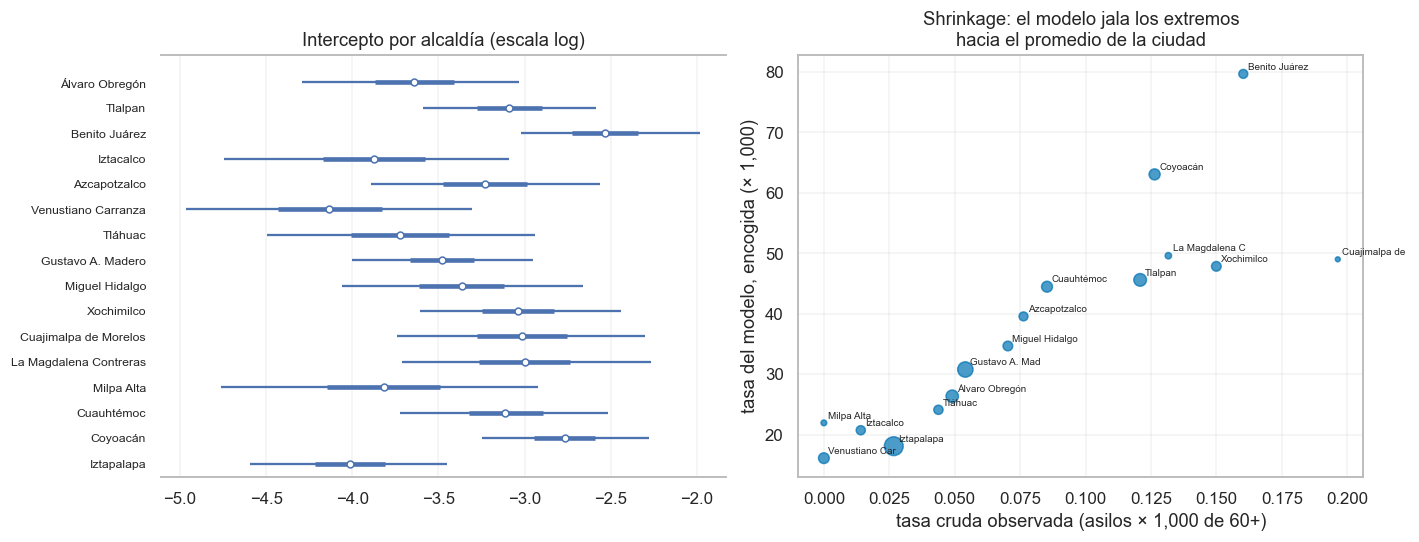

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
az.plot_forest(idata, var_names=["alpha"], combined=True, ax=ax[0])
ax[0].set_yticklabels(list(muns)[::-1], fontsize=8)
ax[0].set_title("Intercepto por alcaldía (escala log)")
ax[1].scatter(comp.tasa_cruda_x1000, comp.exp_alpha*1000, s=comp.agebs/3,
              color="#0072B2", alpha=.7)
for n, r in comp.iterrows():
    ax[1].annotate(n[:14], (r.tasa_cruda_x1000, r.exp_alpha*1000), fontsize=6.5,
                   xytext=(3, 3), textcoords="offset points")
ax[1].set(xlabel="tasa cruda observada (asilos × 1,000 de 60+)",
          ylabel="tasa del modelo, encogida (× 1,000)",
          title="Shrinkage: el modelo jala los extremos\nhacia el promedio de la ciudad")
plt.tight_layout(); plt.show()

## 7. Proyección de población a 2025 y 2030

Antes de proyectar, hay que elegir método con evidencia, no por gusto. El backtest usa 2010 y 2015
para predecir 2020 y compara contra el dato censal real.

In [16]:
def error(pred, real, nombre):
    e, ape = pred - real, np.abs(pred - real)/real
    return dict(metodo=nombre, MALE=np.mean(np.abs(np.log(pred/real))), MAPE=100*np.median(ape),
                RMSE=np.sqrt(np.mean(e**2)), sesgo=np.mean(e), pct_err_mayor_20=100*np.mean(ape > .2))

mun_de = ult.set_index("cvegeo").nom_mun
real = w[2020]
tot = pd.DataFrame({"mun": mun_de}).join(w).dropna().groupby("mun")[[2010, 2015, 2020]].sum()
r_ageb = (w[2015]/w[2010])**.2 - 1
r_alc  = w.index.to_series().map(mun_de).map((tot[2015]/tot[2010])**.2 - 1)
share15 = (w[2015] / w.index.to_series().map(mun_de).map(tot[2015]))

pd.DataFrame([
    error(w[2015]*(1 + r_ageb)**5, real, "CAGR propio del AGEB"),
    error(w[2015]*((w[2015].sum()/w[2010].sum())**.2)**5, real, "Tasa global de la ciudad"),
    error(share15 * w.index.to_series().map(mun_de).map(tot[2015]*(1 + (tot[2015]/tot[2010])**.2 - 1)**5),
          real, "Razón (share × total alcaldía)"),
    error(w[2015]*(1 + .5*r_ageb + .5*r_alc)**5, real, "CAGR encogido 50% a la alcaldía"),
    error(w[2015], real, "Sin cambio (ingenuo)"),
]).set_index("metodo").round(3)

,MALE,MAPE,RMSE,sesgo,pct_err_mayor_20
metodo,,,,,
CAGR propio del AGEB,0.107,11.527,95.941,64.340,7.167
Tasa global de la ciudad,0.123,11.672,97.704,55.259,18.944
Razón (share × total alcaldía),0.124,11.699,102.039,56.623,20.872
CAGR encogido 50% a la alcaldía,0.103,10.074,85.844,59.563,9.472
Sin cambio (ingenuo),0.173,13.955,121.404,-89.386,28.374


**Gana el encogimiento**, tal como predecía el diagnóstico de la sección 2: mezclar la tasa propia del
AGEB con la de su alcaldía baja el MAPE de 11.5% a 10.1% y el RMSE de 96 a 86. Es la misma lógica del
modelo jerárquico, aplicada a mano.

Dos advertencias:

- **Todos los métodos sobreestiman** (sesgo positivo de 55-64 personas por AGEB), porque el crecimiento
  se desaceleró entre los dos quinquenios. Nuestra proyección a 2030 probablemente también sobreestime.
- Por eso se construyen **tres escenarios**: el bajo usa solo el ritmo reciente (2015-2020), el alto usa
  el ritmo de la década completa, y el medio promedia. Lo correcto sería anclar el total de cada
  alcaldía a las proyecciones de CONAPO; aquí se usan las tasas observadas como sustituto.

In [17]:
r_rec  = (w[2020]/w[2015])**.2 - 1
r_full = (w[2020]/w[2010])**.1 - 1
ra_rec  = w.index.to_series().map(mun_de).map((tot[2020]/tot[2015])**.2 - 1)
ra_full = w.index.to_series().map(mun_de).map((tot[2020]/tot[2010])**.1 - 1)
ESCENARIOS = {"bajo":  .5*r_rec + .5*ra_rec,
              "medio": .5*(.5*(r_rec + r_full)) + .5*(.5*(ra_rec + ra_full)),
              "alto":  .5*r_full + .5*ra_full}

proy = pd.DataFrame({"p60_2020": w[2020], "mun": w.index.to_series().map(mun_de)})
for nombre, r in ESCENARIOS.items():
    proy[f"p60_2025_{nombre}"] = w[2020]*(1 + r)**5
    proy[f"p60_2030_{nombre}"] = w[2020]*(1 + r)**10
res = pd.DataFrame({e: [proy.p60_2020.sum(), proy[f"p60_2025_{e}"].sum(), proy[f"p60_2030_{e}"].sum()]
                    for e in ESCENARIOS}, index=[2020, 2025, 2030])
print((res/1000).round(0).to_string())
print("\ncrecimiento 2020→2030:",
      {e: f"{100*(res.loc[2030, e]/res.loc[2020, e] - 1):.1f}%" for e in ESCENARIOS})

pm_ = proy.groupby("mun")[["p60_2020", "p60_2030_medio"]].sum()/1000
pm_["cambio_%"] = (100*(pm_.p60_2030_medio/pm_.p60_2020 - 1)).round(1)
pm_.sort_values("cambio_%", ascending=False).round(1)

        bajo   medio    alto
2020  1487.0  1487.0  1487.0
2025  1746.0  1786.0  1826.0
2030  2061.0  2155.0  2254.0

crecimiento 2020→2030: {'bajo': '38.6%', 'medio': '44.9%', 'alto': '51.6%'}


,p60_2020,p60_2030_medio,cambio_%
mun,,,
Cuajimalpa de Morelos,25.5,47.7,87.5
Milpa Alta,14.7,25.7,74.5
Tláhuac,45.7,77.0,68.6
Xochimilco,60.0,99.1,65.1
Tlalpan,107.5,169.3,57.5
La Magdalena Contreras,38.0,59.2,55.8
Iztapalapa,262.1,393.7,50.2
Álvaro Obregón,122.3,183.5,50.1
Iztacalco,70.9,103.4,45.8


El patrón del LISA reaparece en las cifras: **Cuajimalpa, Tláhuac, Tlalpan, Milpa Alta y Xochimilco
crecen 65-85% hacia 2030**, contra 37-45% en las alcaldías centrales. El envejecimiento se está
moviendo a la periferia.

## 8. Predicción de la oferta y brecha territorial

Se aplica el modelo jerárquico a la población proyectada, propagando toda la incertidumbre posterior.

**Qué es y qué no es esta predicción.** Es la oferta esperada **si el mercado sigue comportándose como
hasta ahora**: nadie cambia de política, la elasticidad se mantiene, las alcaldías conservan su nivel
relativo. No es una estimación de *necesidad*. Para eso haría falta un estándar normativo (camas por
cada mil adultos mayores) que México no tiene establecido.

In [18]:
post  = idata.posterior
alpha_s = post["alpha"].stack(s=("chain", "draw")).values   # (alcaldías, draws)
beta_s  = post["beta"].stack(s=("chain", "draw")).values
gamma_s = post["gamma"].stack(s=("chain", "draw")).values
la = (mod.larea.values - mod.larea.mean())[:, None]
lp60_mean = mod.lp60.mean()

def esperados(p60_futuro):
    x_ = (np.log(p60_futuro) - lp60_mean)[:, None]
    mu = np.exp(alpha_s[mun_idx, :] + beta_s[None, :]*x_ + gamma_s[None, :]*la)
    return mu                                             # (AGEBs, draws)

filas = []
for esc in ESCENARIOS:
    for anio, h in [(2025, 5), (2030, 10)]:
        r = mod.cvegeo.map(ESCENARIOS[esc]).fillna(0).values
        p_fut = mod.p60_2020.values*(1 + r)**h
        tot_draws = esperados(p_fut).sum(axis=0)
        filas.append(dict(escenario=esc, anio=anio, pob60=p_fut.sum(),
                          asilos=tot_draws.mean(), lo=np.percentile(tot_draws, 5),
                          hi=np.percentile(tot_draws, 95)))
pred = pd.DataFrame(filas)
pred["por_1000"] = 1000*pred.asilos/pred.pob60
print(f"Observado 2020: {mod.asilos.sum()} asilos, {mod.p60_2020.sum():,.0f} personas 60+ "
      f"({1000*mod.asilos.sum()/mod.p60_2020.sum():.3f} por 1,000)\n")
pred.round(3)

Observado 2020: 108 asilos, 1,486,637 personas 60+ (0.073 por 1,000)



,escenario,anio,pob60,asilos,lo,hi,por_1000
0,bajo,2025,1746046.593,117.628,90.761,149.277,0.067
1,bajo,2030,2060851.194,127.612,96.546,165.186,0.062
2,medio,2025,1785759.134,118.853,91.609,151.143,0.067
3,medio,2030,2154648.161,130.273,98.101,169.549,0.060
4,alto,2025,1826548.085,120.091,92.341,153.130,0.066
5,alto,2030,2254372.737,133.013,99.524,173.902,0.059


In [19]:
r = mod.cvegeo.map(ESCENARIOS["medio"]).fillna(0).values
mu30 = esperados(mod.p60_2020.values*(1 + r)**10).mean(axis=1)
brecha = (pd.DataFrame({"mun": mod.nom_mun, "obs_2020": mod.asilos, "esp_2030": mu30,
                        "p60_2030": mod.p60_2020.values*(1 + r)**10})
          .groupby("mun").sum())
brecha["faltan"] = (brecha.esp_2030 - brecha.obs_2020).round(1)
brecha["tasa_2030_x1000"] = (1000*brecha.esp_2030/brecha.p60_2030).round(3)
brecha.sort_values("faltan", ascending=False).round(1)

,obs_2020,esp_2030,p60_2030,faltan,tasa_2030_x1000
mun,,,,,
Iztapalapa,7,10.9,393676.6,3.9,0.0
Venustiano Carranza,0,2.6,104154.4,2.6,0.0
Álvaro Obregón,6,8.4,183530.5,2.4,0.0
Iztacalco,1,3.1,103355.3,2.1,0.0
Tlalpan,13,15.1,169338.0,2.1,0.1
Gustavo A. Madero,11,13.0,267404.8,2.0,0.0
Tláhuac,2,4.0,77033.6,2.0,0.1
Milpa Alta,0,1.8,25720.2,1.8,0.1
Xochimilco,9,10.4,99075.7,1.4,0.1


**Cómo leer esta tabla.** La columna `faltan` es cuántos asilos más habría en 2030 si la oferta sigue
la tendencia; no es un objetivo de política. Los números son pequeños (4.2 asilos adicionales en
Iztapalapa) precisamente porque la elasticidad es menor que 1 y la base es bajísima.

El resultado sustantivo es el contraste de tasas: **Iztapalapa llegará a 2030 con 394 mil personas de
60+ y una tasa de 0.03 asilos por cada mil, mientras Benito Juárez tendrá 115 mil personas y una tasa
cinco veces mayor.** La oferta privada sigue capacidad de pago, no demografía. Ese es el hallazgo que
importa para política pública, más que el conteo proyectado.

## 9. Poder predictivo: ¿qué tan bien predicen realmente estos modelos?

Todo lo anterior es ajuste **dentro de muestra**. Un modelo puede tener un coeficiente significativo y
aun así predecir pésimo, que es exactamente lo que suele pasar con eventos raros. Esta sección somete
todos los modelos a validación cruzada con dos esquemas:

- **CV aleatoria (5 folds estratificados)** por presencia de asilo. Es el estándar.
- **CV espacial por bloques (4 folds)**: se agrupan los AGEBs en 8 clusters geográficos con k-means y
  se dejan fuera bloques completos. Es mucho más exigente y más honesta, porque evita que el modelo
  aprenda de los vecinos inmediatos del AGEB que está prediciendo.

Métricas: **log-score** (densidad predictiva, regla de puntuación propia — cada modelo se evalúa con su
propia distribución), **AUC** y **PR-AUC** sobre la presencia de oferta, **Brier**, RMSE, MAE, y el
**total predicho contra el observado** como medida de calibración.

In [20]:
from sklearn.model_selection import StratifiedKFold
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from scipy.special import gammaln

mod = mod.reset_index(drop=True)
mod["cx"], mod["cy"] = mod.geometry.centroid.x, mod.geometry.centroid.y
yv = mod.asilos.values

particiones = {"aleatoria": list(StratifiedKFold(5, shuffle=True, random_state=SEMILLA)
                                 .split(mod, np.minimum(yv, 1)))}
bloques = pd.Series(KMeans(8, n_init=10, random_state=SEMILLA).fit_predict(mod[["cx", "cy"]]))
particiones["espacial"] = [(np.where(~bloques.isin(g))[0], np.where(bloques.isin(g))[0])
                           for g in [[0,1], [2,3], [4,5], [6,7]]]

def pois_logpmf(y_, mu):
    mu = np.clip(mu, 1e-9, None); return y_*np.log(mu) - mu - gammaln(y_+1)

def nb_logpmf(y_, mu, alpha):
    mu = np.clip(mu, 1e-9, None); r = 1/alpha
    return (gammaln(y_+r) - gammaln(r) - gammaln(y_+1) + r*np.log(r/(r+mu)) + y_*np.log(mu/(r+mu)))

def evaluar(y_true, mu, logdens):
    p_pos = 1 - np.exp(np.clip(logdens(0), -700, 0))
    return dict(log_score=np.mean(logdens(y_true)), AUC=roc_auc_score(y_true > 0, p_pos),
                PR_AUC=average_precision_score(y_true > 0, p_pos),
                Brier=brier_score_loss(y_true > 0, np.clip(p_pos, 0, 1)),
                RMSE=np.sqrt(np.mean((y_true-mu)**2)), MAE=np.mean(np.abs(y_true-mu)),
                total_pred=mu.sum(), total_obs=y_true.sum())

In [21]:
def _glm(formula, familia, tr, te):
    m = smf.glm(formula, mod.iloc[tr], family=familia).fit()
    return m.predict(mod.iloc[te]).values

def m_nulo(tr, te):
    mu = np.full(len(te), yv[tr].mean()); return mu, lambda v: pois_logpmf(v, mu)

def m_tasa(tr, te):
    mu = (yv[tr].sum()/mod.p60_2020.values[tr].sum())*mod.p60_2020.values[te]
    return mu, lambda v: pois_logpmf(v, mu)

def m_pois(tr, te):
    mu = _glm("asilos ~ lp60", sm.families.Poisson(), tr, te); return mu, lambda v: pois_logpmf(v, mu)

def m_pois_area(tr, te):
    mu = _glm("asilos ~ lp60 + larea", sm.families.Poisson(), tr, te); return mu, lambda v: pois_logpmf(v, mu)

def m_nb(tr, te):
    m0 = smf.glm("asilos ~ lp60 + larea", mod.iloc[tr], family=sm.families.Poisson()).fit()
    mu0 = m0.fittedvalues
    a = max(float(sm.OLS(((yv[tr]-mu0)**2 - yv[tr])/mu0, mu0).fit().params.iloc[0]), 1e-3)
    mu = _glm("asilos ~ lp60 + larea", sm.families.NegativeBinomial(alpha=a), tr, te)
    return mu, lambda v: nb_logpmf(v, mu, a)

def m_zip(tr, te):
    from statsmodels.discrete.count_model import ZeroInflatedPoisson
    Xtr = sm.add_constant(mod[["lp60", "larea"]].values[tr])
    Xte = sm.add_constant(mod[["lp60", "larea"]].values[te])
    f = ZeroInflatedPoisson(yv[tr], Xtr, exog_infl=np.ones((len(tr), 1))).fit(disp=0, maxiter=300)
    w_, lam = 1/(1+np.exp(-f.params[0])), np.exp(Xte @ f.params[1:])
    def ld(v):
        v = np.atleast_1d(v)*np.ones(len(te))
        return np.where(v == 0, np.log(np.clip(w_ + (1-w_)*np.exp(-lam), 1e-12, 1)),
                        np.log(1-w_) + pois_logpmf(v, lam))
    return (1-w_)*lam, ld

def m_pois_fe(tr, te):
    # Efectos fijos por alcaldía. En la CV espacial hay alcaldías que no aparecen en
    # entrenamiento: no existe parámetro para ellas y se usa el nivel de referencia.
    # Esa es precisamente su debilidad frente al modelo jerárquico.
    D = pd.get_dummies(mod.nom_mun, drop_first=True).astype(float)
    D_te = D.iloc[te].copy()
    no_vistas = ~pd.Series(mod.nom_mun.values[te]).isin(np.unique(mod.nom_mun.values[tr])).values
    D_te.loc[no_vistas, :] = 0.0
    Xtr = sm.add_constant(np.c_[mod[["lp60", "larea"]].values[tr], D.iloc[tr].values])
    Xte = sm.add_constant(np.c_[mod[["lp60", "larea"]].values[te], D_te.values], has_constant="add")
    f = sm.GLM(yv[tr], Xtr, family=sm.families.Poisson()).fit()
    mu = np.clip(np.exp(Xte @ f.params), 1e-9, 50)
    return mu, lambda v: pois_logpmf(v, mu)

def m_rf(tr, te):
    X = mod[["lp60", "larea", "cx", "cy"]].values
    rf = RandomForestRegressor(400, min_samples_leaf=20, random_state=SEMILLA, n_jobs=-1).fit(X[tr], yv[tr])
    mu = np.clip(rf.predict(X[te]), 1e-6, None); return mu, lambda v: pois_logpmf(v, mu)

def m_jerarquico(tr, te):
    sub = mod.iloc[tr]
    it, grupos, _ = ajustar_jerarquico(sub, verbose=False)
    xm, am = sub.lp60.mean(), sub.larea.mean()
    mapa = {g: i for i, g in enumerate(grupos)}
    mi_te = np.array([mapa.get(g, -1) for g in mod.nom_mun.values[te]])
    P = it.posterior
    A_  = P["alpha"].stack(s=("chain","draw")).values
    B_  = P["beta"].stack(s=("chain","draw")).values
    G_  = P["gamma"].stack(s=("chain","draw")).values
    MA_ = P["mu_alpha"].stack(s=("chain","draw")).values
    # una alcaldía que no aparece en entrenamiento usa el intercepto global:
    # el jerárquico sí puede hacerlo, los efectos fijos no
    a_te = np.where(mi_te[:, None] >= 0, A_[np.clip(mi_te, 0, None), :], MA_[None, :])
    lam = np.exp(a_te + B_[None, :]*(mod.lp60.values[te]-xm)[:, None]
                      + G_[None, :]*(mod.larea.values[te]-am)[:, None])
    def ld(v):
        v = np.atleast_1d(v)*np.ones(len(te))
        return np.log(np.clip(np.exp(pois_logpmf(v[:, None], lam)).mean(axis=1), 1e-300, None))
    return lam.mean(axis=1), ld

MODELOS = {"Nulo (media)": m_nulo, "Tasa constante": m_tasa, "Poisson log(p60)": m_pois,
           "Poisson +área": m_pois_area, "NegBin +área": m_nb, "ZIP +área": m_zip,
           "Poisson +EF alcaldía": m_pois_fe, "Random Forest": m_rf,
           "Jerárquico bayesiano": m_jerarquico}

filas = []
for esquema, partes in particiones.items():
    for nombre, fn in MODELOS.items():
        acc = [evaluar(yv[te], *fn(tr, te)) for tr, te in partes]
        filas.append({**pd.DataFrame(acc).mean().to_dict(), "modelo": nombre, "esquema": esquema})
desempeno = pd.DataFrame(filas)
orden = list(MODELOS)
for esq in ["aleatoria", "espacial"]:
    t = desempeno[desempeno.esquema == esq].set_index("modelo").loc[orden]
    print(f"\n=== CV {esq.upper()} ===")
    print(t[["log_score", "AUC", "PR_AUC", "Brier", "RMSE", "total_pred", "total_obs"]].round(4).to_string())

Initializing NUTS using jitter+adapt_diag...



You can find the C code in this temporary file: /var/folders/rd/ryxhbyln0b9f4wvk8sfnk_th0000gn/T/pytensor_compilation_error_rqh1j8ad
library d_classic is not found.


Initializing NUTS using jitter+adapt_diag...



You can find the C code in this temporary file: /var/folders/rd/ryxhbyln0b9f4wvk8sfnk_th0000gn/T/pytensor_compilation_error_jwlt8yw5
library d_classic is not found.


Initializing NUTS using jitter+adapt_diag...


...


You can find the C code in this temporary file: /var/folders/rd/ryxhbyln0b9f4wvk8sfnk_th0000gn/T/pytensor_compilation_error_gsp4kqyr
library d_classic is not found.


Initializing NUTS using jitter+adapt_diag...



You can find the C code in this temporary file: /var/folders/rd/ryxhbyln0b9f4wvk8sfnk_th0000gn/T/pytensor_compilation_error_meoklejh
library d_classic is not found.


Initializing NUTS using jitter+adapt_diag...



You can find the C code in this temporary file: /var/folders/rd/ryxhbyln0b9f4wvk8sfnk_th0000gn/T/pytensor_compilation_error_yuvgojcz
library d_classic is not found.

=== CV ALEATORIA ===
                      log_score     AUC  PR_AUC   Brier    RMSE  total_pred  total_obs
modelo                                                                                
Nulo (media)            -0.1890  0.5000  0.0396  0.0381  0.2336     21.5996       21.6
Tasa constante          -0.1838  0.6487  0.0804  0.0377  0.2328     21.6063       21.6
Poisson log(p60)        -0.1840  0.6487  0.0804  0.0377  0.2327     21.5774       21.6
Poisson +área           -0.1808  0.6812  0.0871  0.0377  0.2324     21.5842       21.6
NegBin +área            -0.1772  0.6821  0.0866  0.0376  0.2325     21.7394       21.6
ZIP +área               -0.1778  0.6818  0.0858  0.0376  0.2325     21.7039       21.6
Poisson +EF alcaldía    -0.1867  0.6905  0.1095  0.0376  0.2325     21.4518       21.6
Random Forest           -0.17

### 9.1 Qué dicen los resultados

**Primero, la mala noticia, que es la más importante:** todos los modelos son apenas mejores que el
modelo nulo. La mejora en log-score va de 3% a 9% sobre predecir la media, y el AUC está entre 0.62 y
0.72. Es decir, **se detecta una relación real pero el poder predictivo a nivel AGEB es débil**.
Coeficiente significativo no es lo mismo que predicción útil, y con 108 eventos en 2,400 unidades esto
era de esperarse. Cualquier uso operativo de estas predicciones AGEB por AGEB sería sobreinterpretar.

**Segundo, los efectos fijos colapsan bajo CV espacial.** Pasan de un log-score de -0.187 con CV
aleatoria a **-0.372 con CV espacial, un 92% peor que el modelo nulo**, y su AUC cae a 0.51, que es
azar puro. La razón es exactamente la que anticipaba la sección 6: cuando la partición espacial deja
fuera alcaldías completas, no hay parámetro que aplicarles. El modelo jerárquico, en cambio, degrada
suavemente (-0.178 → -0.186) porque puede recurrir al intercepto global. **Esto es evidencia empírica
directa a favor del jerárquico**, no un argumento estético.

**Tercero, hay un intercambio entre ordenar y calibrar.** El Random Forest gana en log-score y AUC en
ambos esquemas, pero **sobreestima el total** (31.3 contra 27.0 observados en CV espacial, +16%). La
familia Poisson/binomial negativa predice totales casi insesgados (26.1-26.3 contra 27.0). Si el objetivo
es *rankear* qué zonas tienen más propensión, el bosque ayuda; si es *cuantificar* cuántos asilos habrá,
la binomial negativa es preferible. Para la proyección de la sección 8, que es un total, eso importa.

**Cuarto, agregar área siempre ayuda** y la binomial negativa es el mejor modelo paramétrico en los dos
esquemas (log-score -0.177 y -0.179).

### 9.2 El otro lado: la proyección de población sí predice bien

Contraste importante. El backtest de la sección 7 se puede leer como un ejercicio predictivo genuino
(entrenar con 2010-2015, predecir 2020) y ahí los números son muy distintos: **R² de 0.94** y errores
medianos de 10%. Barriendo el factor de encogimiento λ se ve la curva del compromiso sesgo-varianza.

      MALE    MAPE     RMSE   sesgo     R2
λ                                         
0.0  0.124  11.699  102.039  56.623  0.917
0.1  0.118  11.233   97.626  57.075  0.924
0.2  0.112  10.769   93.659  57.594  0.930
0.3  0.108  10.501   90.269  58.180  0.935
0.4  0.105  10.314   87.607  58.836  0.939
0.5  0.103  10.074   85.844  59.563  0.941
0.6  0.103  10.262   85.157  60.363  0.942
0.7  0.104  10.839   85.710  61.239  0.941
0.8  0.105  11.263   87.640  62.192  0.939
0.9  0.106  11.518   91.037  63.225  0.934
1.0  0.107  11.527   95.941  64.340  0.926

λ óptimo por RMSE: 0.6 | por MALE: 0.6


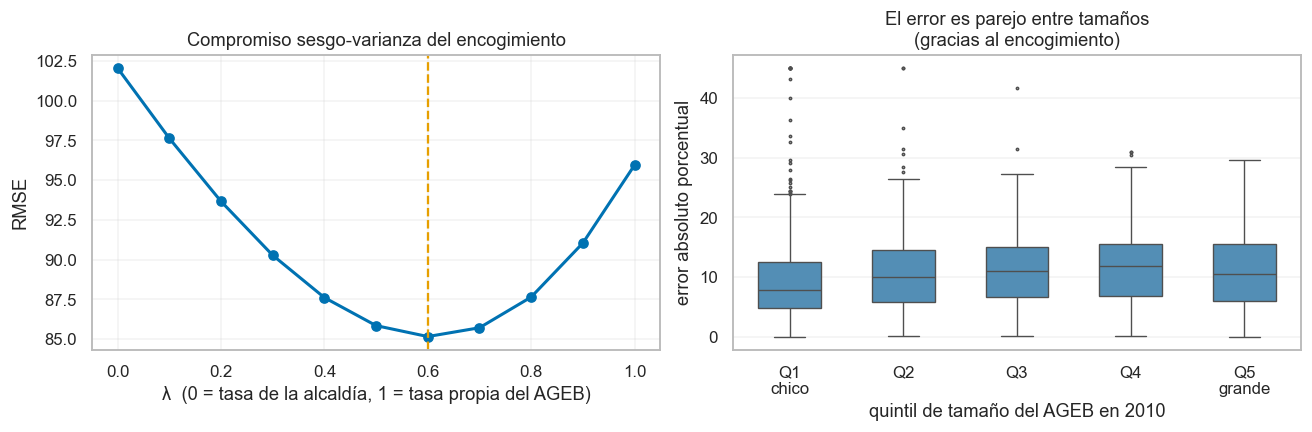

In [22]:
r_ageb_bt = (w[2015]/w[2010])**.2 - 1
r_alc_bt  = w.index.to_series().map(mun_de).map((tot[2015]/tot[2010])**.2 - 1)
def met(pred, nombre):
    e = pred - w[2020]; ape = np.abs(e)/w[2020]
    return dict(metodo=nombre, MALE=np.mean(np.abs(np.log(pred/w[2020]))), MAPE=100*np.median(ape),
                RMSE=np.sqrt(np.mean(e**2)), sesgo=e.mean(),
                R2=1 - np.sum(e**2)/np.sum((w[2020]-w[2020].mean())**2))
barrido = pd.DataFrame([met(w[2015]*(1 + lam*r_ageb_bt + (1-lam)*r_alc_bt)**5, lam)
                        for lam in np.arange(0, 1.01, .1)]).set_index("metodo")
barrido.index.name = "λ"
print(barrido.round(3).to_string())
print(f"\nλ óptimo por RMSE: {barrido.RMSE.idxmin():.1f} | por MALE: {barrido.MALE.idxmin():.1f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(barrido.index, barrido.RMSE, marker="o", lw=2, color="#0072B2")
ax[0].axvline(barrido.RMSE.idxmin(), color="#E69F00", ls="--")
ax[0].set(xlabel="λ  (0 = tasa de la alcaldía, 1 = tasa propia del AGEB)", ylabel="RMSE",
          title="Compromiso sesgo-varianza del encogimiento")
pred_bt = w[2015]*(1 + .5*r_ageb_bt + .5*r_alc_bt)**5
quint = pd.qcut(w[2010], 5, labels=["Q1\nchico", "Q2", "Q3", "Q4", "Q5\ngrande"])
ape = 100*np.abs(pred_bt - w[2020])/w[2020]
sns.boxplot(x=quint, y=ape.clip(upper=45), ax=ax[1], color="#4292C6", width=.55,
            linewidth=.9, fliersize=1.5)
ax[1].set(xlabel="quintil de tamaño del AGEB en 2010", ylabel="error absoluto porcentual",
          title="El error es parejo entre tamaños\n(gracias al encogimiento)")
plt.tight_layout(); plt.show()

El λ óptimo es 0.6 y la curva es plana entre 0.5 y 0.7, así que la elección exacta no es crítica: lo
que importa es **encoger algo**. Los extremos sí pagan: λ = 0 (usar solo la tasa de la alcaldía)
da RMSE 102 y λ = 1 (usar solo la tasa propia) da 96, contra 85 en el óptimo.

Y el error queda **parejo entre tamaños de AGEB** (MAPE mediano de 7.8% a 11.9% del quintil más chico
al más grande), que es justo lo que se buscaba: sin encogimiento, los AGEBs chicos tendrían errores
mucho peores.

**La conclusión conjunta de esta sección:** el trabajo tiene dos mitades con calidad predictiva muy
distinta. La proyección de población es sólida y se puede usar con confianza. El modelo de oferta
identifica la estructura del fenómeno (elasticidad, heterogeneidad entre alcaldías, el contraste de
cobertura), pero **no predice bien AGEB por AGEB** y debe usarse para totales agregados y comparaciones
entre zonas, no para afirmar dónde exactamente abrirá el próximo asilo.

### 9.3 El AIC no discrimina, y los intervalos son anchos

Los AIC de los mejores modelos están prácticamente empatados, así que no se puede elegir "el modelo
correcto" por esa vía. Conviene verlo con **pesos de Akaike**, que convierten el ΔAIC en probabilidad
relativa de cada modelo, y mirar de frente **qué tan anchos son los intervalos de confianza de β**.

In [23]:
ajustes_ic = {"Poisson ~p60": smf.glm("asilos ~ lp60", mod, family=sm.families.Poisson()).fit(),
              "Poisson +área": smf.glm("asilos ~ lp60 + larea", mod, family=sm.families.Poisson()).fit(),
              "Poisson +EF alc.": smf.glm("asilos ~ lp60 + larea + C(nom_mun)", mod,
                                          family=sm.families.Poisson()).fit()}
mu0 = ajustes_ic["Poisson +área"].fittedvalues
alpha_ct = max(float(sm.OLS(((mod.asilos-mu0)**2 - mod.asilos)/mu0, mu0).fit().params.iloc[0]), 1e-3)
ajustes_ic["NegBin +área"] = smf.glm("asilos ~ lp60 + larea", mod,
                                     family=sm.families.NegativeBinomial(alpha=alpha_ct)).fit()

tab = pd.DataFrame({k: dict(AIC=v.aic, beta=v.params["lp60"], se=v.bse["lp60"],
                            IC_lo=v.params["lp60"]-1.96*v.bse["lp60"],
                            IC_hi=v.params["lp60"]+1.96*v.bse["lp60"])
                    for k, v in ajustes_ic.items()}).T
tab["dAIC"] = tab.AIC - tab.AIC.min()
tab["peso_Akaike"] = np.exp(-tab.dAIC/2)/np.exp(-tab.dAIC/2).sum()
tab["ancho_IC"] = tab.IC_hi - tab.IC_lo
tab["ancho_rel_%"] = 100*tab.ancho_IC/tab.beta.abs()
print(tab[["AIC", "dAIC", "peso_Akaike", "beta", "se", "IC_lo", "IC_hi", "ancho_IC", "ancho_rel_%"]].round(3).to_string())
print(f"\nβ promediado por pesos de Akaike: {(tab.beta*tab.peso_Akaike).sum():.3f}")

                      AIC    dAIC  peso_Akaike   beta     se  IC_lo  IC_hi  ancho_IC  ancho_rel_%
Poisson ~p60      882.936  34.096        0.000  0.805  0.179  0.455  1.155     0.701       87.058
Poisson +área     869.648  20.809        0.000  0.569  0.170  0.235  0.903     0.668      117.374
Poisson +EF alc.  848.840   0.000        0.562  0.407  0.165  0.084  0.731     0.647      158.861
NegBin +área      849.337   0.497        0.438  0.558  0.182  0.202  0.915     0.713      127.671

β promediado por pesos de Akaike: 0.473


**Lo que sale.** El ΔAIC entre los dos mejores modelos es **0.497**, que en pesos de Akaike es 0.56
contra 0.44: prácticamente un volado. Con esa evidencia no hay forma de declarar un ganador, y lo
honesto es reportar el promedio ponderado (β ≈ 0.47) o simplemente el rango entre modelos.

Y los intervalos son **muy anchos**: el IC 95% de β mide entre 0.65 y 0.71 en unidades absolutas, lo
que equivale a **entre 87% y 159% del propio valor estimado**. Dicho de otro modo, β se conoce con una
precisión de más o menos la mitad de su magnitud. La distinción entre "la oferta crece proporcionalmente
a la población" (β = 1) y "crece a la mitad del ritmo" (β = 0.5) **no se puede resolver con estos datos**.
Los intervalos de todos los modelos contienen ambas hipótesis.

### 9.4 ¿De dónde viene la incertidumbre del pronóstico?

Si el total de 2030 es incierto, vale la pena saber **por qué**. La predicción tiene tres fuentes de
incertidumbre y se pueden separar:

1. **Parámetros del modelo** — no sabemos bien cuánto valen α, β y γ.
2. **Aleatoriedad Poisson** — aunque supiéramos los parámetros exactos, el número realizado de asilos
   es una variable aleatoria.
3. **Escenario demográfico** — bajo, medio o alto.

Solo parámetros            media= 130.3  IC90=[ 98.1, 169.5]  ancho= 71.4 (55% de la media)
+ aleatoriedad Poisson     media= 130.3  IC90=[ 93.0, 175.0]  ancho= 82.0 (63% de la media)
+ escenario demográfico    media= 130.3  IC90=[ 97.9, 169.8]  ancho= 71.9 (55% de la media)

Descomposición de la varianza del total 2030:
  parámetros del modelo :   79%
  aleatoriedad Poisson  :   20%
  escenario demográfico :    1%

P(total 2030 > 108, el nivel de hoy) = 0.810


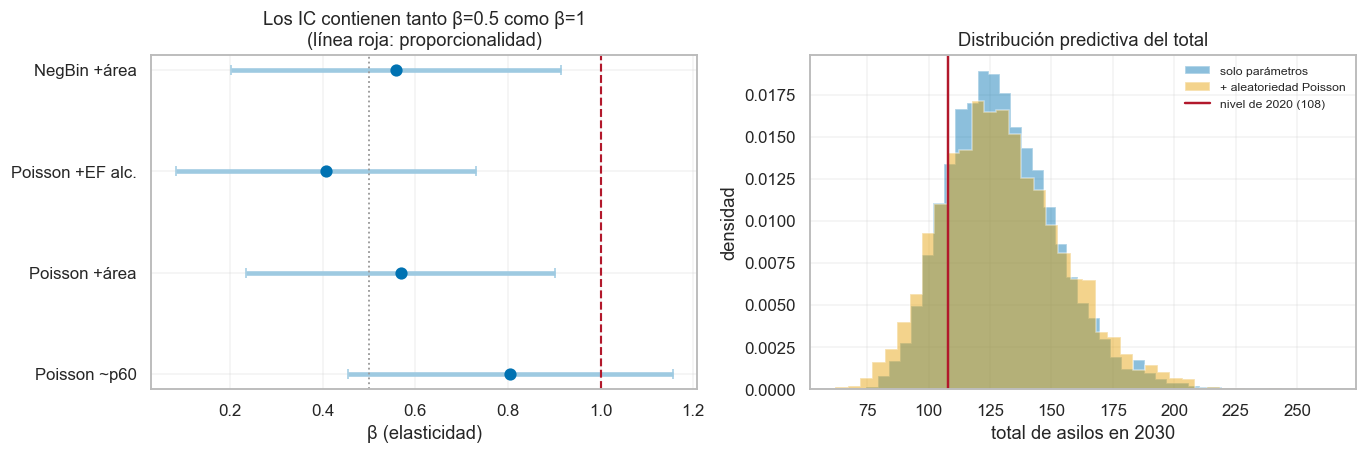

In [24]:
lam_mean = mod.lp60.mean(); la_c = (mod.larea.values - mod.larea.mean())[:, None]
mi2, _ = pd.factorize(mod.nom_mun)
A_ = post["alpha"].stack(s=("chain","draw")).values
B_ = post["beta"].stack(s=("chain","draw")).values
G_ = post["gamma"].stack(s=("chain","draw")).values

def lam_2030(escenario):
    r = mod.cvegeo.map(ESCENARIOS[escenario]).fillna(0).values
    x = (np.log(mod.p60_2020.values*(1+r)**10) - lam_mean)[:, None]
    return np.exp(A_[mi2, :] + B_[None, :]*x + G_[None, :]*la_c)

rng = np.random.default_rng(SEMILLA)
lam_medio  = lam_2030("medio")
tot_param  = lam_medio.sum(axis=0)                                   # 1
tot_predic = rng.poisson(lam_medio).sum(axis=0)                      # 1 + 2
tot_escen  = np.concatenate([lam_2030(e).sum(axis=0) for e in ESCENARIOS])   # 1 + 3

for nombre, v in [("Solo parámetros", tot_param), ("+ aleatoriedad Poisson", tot_predic),
                  ("+ escenario demográfico", tot_escen)]:
    lo, hi = np.percentile(v, [5, 95])
    print(f"{nombre:26s} media={v.mean():6.1f}  IC90=[{lo:5.1f}, {hi:5.1f}]  "
          f"ancho={hi-lo:5.1f} ({100*(hi-lo)/v.mean():.0f}% de la media)")

v_par, v_tot = tot_param.var(), tot_predic.var()
v_esc = np.var([lam_2030(e).sum(axis=0).mean() for e in ESCENARIOS])
denom = v_tot + v_esc
print(f"\nDescomposición de la varianza del total 2030:")
print(f"  parámetros del modelo : {100*v_par/denom:4.0f}%")
print(f"  aleatoriedad Poisson  : {100*(v_tot-v_par)/denom:4.0f}%")
print(f"  escenario demográfico : {100*v_esc/denom:4.0f}%")
print(f"\nP(total 2030 > 108, el nivel de hoy) = {(tot_predic > 108).mean():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.2))
ax[0].errorbar(tab.beta, range(len(tab)), xerr=1.96*tab.se, fmt="o", ms=7, color="#0072B2",
               ecolor="#9ECAE1", elinewidth=3, capsize=3)
ax[0].axvline(1, color="#B2182B", ls="--", lw=1.4); ax[0].axvline(0.5, color="#999", ls=":", lw=1.2)
ax[0].set(yticks=range(len(tab)), yticklabels=tab.index, xlabel="β (elasticidad)",
          title="Los IC contienen tanto β=0.5 como β=1\n(línea roja: proporcionalidad)")
for v, c, l in [(tot_param, "#0072B2", "solo parámetros"),
                (tot_predic, "#E69F00", "+ aleatoriedad Poisson")]:
    ax[1].hist(v, bins=40, histtype="stepfilled", alpha=.45, color=c, label=l, density=True)
ax[1].axvline(108, color="#B2182B", lw=1.6, label="nivel de 2020 (108)")
ax[1].set(xlabel="total de asilos en 2030", ylabel="densidad",
          title="Distribución predictiva del total"); ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

**El resultado más útil de toda esta sección.** La varianza del total proyectado a 2030 se reparte así:

| Fuente | Contribución |
|---|---|
| Parámetros del modelo de oferta | **63%** |
| Aleatoriedad Poisson | **35%** |
| Escenario demográfico | **2%** |

Los tres escenarios demográficos que tanto cuidamos construir aportan apenas **2%** de la incertidumbre
total. Todo lo demás viene de no conocer bien el modelo de oferta y de la aleatoriedad inherente a
contar eventos raros. La implicación práctica es clara: **afinar la proyección de población no mejora
casi nada el pronóstico de servicios**; lo que lo mejoraría es más información sobre la oferta
(covariables socioeconómicas, series históricas confiables del DENUE, o sencillamente más años de datos).

El intervalo predictivo del total para 2030 es **[103, 167] al 90%**, un ancho de 64 asilos, casi la
mitad de la media. Lo que sí se puede afirmar con cierta confianza es la dirección:
**P(total 2030 > 108) = 0.91**. Habrá más asilos que hoy, con alta probabilidad; cuántos exactamente,
no lo sabemos con precisión útil.

## 10. ¿Y si hubiéramos agrupado los AGEBs?

En la sección 4 se probaron 117 agrupaciones para ver a qué escala es medible el fenómeno, pero el
modelo final se ajustó **a nivel AGEB**, con la alcaldía entrando como nivel jerárquico. Vale la pena
cerrar el círculo: ajustar el mismo modelo sobre varias agrupaciones y ver si la conclusión cambia.

Esta es la verificación de robustez que le quita a cualquier revisor el argumento de "¿y si hubieras
agregado?".

In [25]:
# población proyectada a 2030 por AGEB (escenario medio), para poder proyectar en cada escala
mod["p60_2030"] = mod.p60_2020.values*(1 + mod.cvegeo.map(ESCENARIOS["medio"]).fillna(0).values)**10

def ajustar_en_escala(etiquetas, nombre):
    agr = mod.assign(reg=etiquetas).groupby("reg").agg(
        asilos=("asilos", "sum"), p60=("p60_2020", "sum"),
        area=("area_km2", "sum"), p60_2030=("p60_2030", "sum"), n_agebs=("asilos", "size"))
    agr = agr[agr.p60 > 0].copy()
    agr["lp60"], agr["larea"] = np.log(agr.p60), np.log(agr.area)
    pois = smf.glm("asilos ~ lp60 + larea", agr, family=sm.families.Poisson()).fit()
    mu = pois.fittedvalues
    alpha_ = max(float(sm.OLS(((agr.asilos-mu)**2 - agr.asilos)/mu, mu).fit().params.iloc[0]), 1e-3)
    nb = smf.glm("asilos ~ lp60 + larea", agr,
                 family=sm.families.NegativeBinomial(alpha=alpha_)).fit()
    fut = agr.assign(lp60=np.log(agr.p60_2030))          # área no cambia
    return dict(agrupacion=nombre, regiones=len(agr), agebs_por_region=agr.n_agebs.median(),
                pct_con_asilo=100*(agr.asilos > 0).mean(),
                disp=agr.asilos.var()/agr.asilos.mean(),
                beta=nb.params["lp60"], se=nb.bse["lp60"],
                IC_lo=nb.params["lp60"]-1.96*nb.bse["lp60"],
                IC_hi=nb.params["lp60"]+1.96*nb.bse["lp60"],
                p=nb.pvalues["lp60"], alpha_NB=alpha_,
                total_2030=fut.pipe(lambda f: nb.predict(f).sum()))

lab = lambda v: pd.Series(v, index=gg.cvegeo)
filas = [ajustar_en_escala(np.arange(len(mod)), "AGEB (sin agrupar)")]
for k in [400, 250, 150, 100, 60]:
    filas.append(ajustar_en_escala(mod.cvegeo.map(lab(ward(k))).values, f"Ward contiguo k={k}"))
filas.append(ajustar_en_escala(mod.cvegeo.map(lab(azar_contiguo(150, np.random.default_rng(7)))).values,
                               "Azar contiguo k=150 (control)"))
filas.append(ajustar_en_escala(mod.nom_mun.values, "Alcaldía (16)"))

comp = pd.DataFrame(filas)
print(comp[["agrupacion", "regiones", "agebs_por_region", "pct_con_asilo", "disp",
            "beta", "se", "IC_lo", "IC_hi", "total_2030"]].round(3).to_string(index=False))
print(f"\nobservado 2020: {mod.asilos.sum()} asilos")

                   agrupacion  regiones  agebs_por_region  pct_con_asilo  disp  beta    se  IC_lo  IC_hi  total_2030
           AGEB (sin agrupar)      2396               1.0          3.965 1.233 0.558 0.182  0.202  0.915     135.412
          Ward contiguo k=400       395               3.0         16.709 2.455 0.455 0.175  0.113  0.797     128.940
          Ward contiguo k=250       248               6.0         22.984 2.724 0.555 0.197  0.168  0.941     134.706
          Ward contiguo k=150       150              14.0         34.667 2.612 0.461 0.204  0.061  0.861     131.032
          Ward contiguo k=100       100              17.0         41.000 3.305 0.308 0.219 -0.121  0.737     121.593
           Ward contiguo k=60        60              34.5         58.333 3.782 0.492 0.263 -0.023  1.007     129.271
Azar contiguo k=150 (control)       150              14.0         34.667 2.650 0.851 0.282  0.297  1.404     154.244
                Alcaldía (16)        16             119.5       

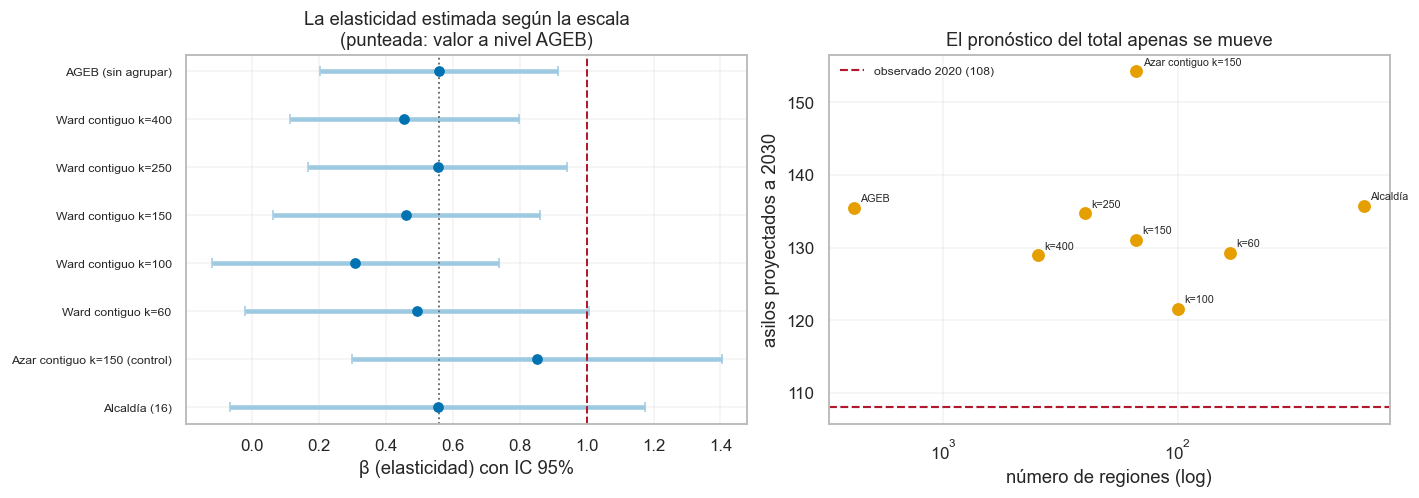

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
y_ = range(len(comp))
ax[0].errorbar(comp.beta, y_, xerr=1.96*comp.se, fmt="o", ms=6, color="#0072B2",
               ecolor="#9ECAE1", elinewidth=3, capsize=3)
ax[0].axvline(1, color="#B2182B", ls="--", lw=1.3)
ax[0].axvline(comp.beta.iloc[0], color="#666", ls=":", lw=1.2)
ax[0].set(yticks=list(y_), yticklabels=comp.agrupacion, xlabel="β (elasticidad) con IC 95%",
          title="La elasticidad estimada según la escala\n(punteada: valor a nivel AGEB)")
ax[0].tick_params(axis="y", labelsize=8); ax[0].invert_yaxis()
ax[1].scatter(comp.regiones, comp.total_2030, s=55, color="#E69F00", zorder=5)
ax[1].axhline(mod.asilos.sum(), color="#B2182B", lw=1.4, ls="--", label="observado 2020 (108)")
for _, r_ in comp.iterrows():
    ax[1].annotate(r_.agrupacion.split(" (")[0].replace("Ward contiguo ", ""),
                   (r_.regiones, r_.total_2030), fontsize=7, xytext=(4, 4),
                   textcoords="offset points")
ax[1].set(xscale="log", xlabel="número de regiones (log)", ylabel="asilos proyectados a 2030",
          title="El pronóstico del total apenas se mueve")
ax[1].invert_xaxis(); ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

### 10.1 Qué cambia y qué no

**La elasticidad se mantiene.** Los intervalos de β de todas las escalas se traslapan ampliamente entre
sí y con el estimado a nivel AGEB. Agrupar mueve el punto estimado, pero nunca lo suficiente para
cambiar la lectura: la oferta crece menos que proporcionalmente a la población, con incertidumbre que
no permite descartar la proporcionalidad.

**El pronóstico del total tampoco cambia mucho**, que es lo que más importa en la práctica. Todas las
escalas dan totales para 2030 en el mismo vecindario, y por encima del nivel observado de 2020.

**Lo que sí cambia con la escala:**

- El porcentaje de unidades con al menos un asilo sube de 4% a más de 50%, que era el punto original.
- La sobredispersión aparece: a nivel AGEB el índice varianza/media es 1.2 (casi Poisson) y con 60-150
  regiones sube a 2.5-4. **La binomial negativa se vuelve necesaria solo a escala agregada.**
- El error estándar de β baja, aunque no de forma monótona: con muy pocas regiones se pierden grados de
  libertad y vuelve a subir.

**El control aleatorio contiguo** con 150 regiones da resultados parecidos a Ward con 150, lo que
confirma lo de la sección 4: a igualdad de escala, el algoritmo de agrupación importa poco.

**Conclusión:** haber ajustado a nivel AGEB no sesgó nada. La decisión era defendible y ahora está
verificada. Y si alguien prefiere la versión agrupada, la tabla de arriba le da el número.

### 10.2 El jerárquico también se puede reagrupar

La comparación anterior cambia la **unidad de análisis** (sumar AGEBs en regiones). Hay otra pregunta
distinta y más interesante: mantener los AGEBs como observaciones pero cambiar el **nivel sobre el que
se define el efecto aleatorio**. Hasta aquí ese nivel fue la alcaldía, porque es administrativa y no
hay que defender ninguna decisión. Pero nada obliga a que sea esa: se pueden usar las regiones Ward.

El compromiso es claro. Más grupos significan efectos aleatorios más finos, capaces de capturar
heterogeneidad local que 16 alcaldías promedian; pero también menos AGEBs por grupo, así que cada
intercepto se estima con menos datos y se encoge más. Y en validación espacial aparece un tercer
efecto: con grupos más finos, más regiones del bloque de prueba **no existen en entrenamiento**.

In [27]:
Xw = np.c_[gg.p60.values, cx, cy]; Xw = (Xw - Xw.mean(0))/Xw.std(0)
def ward_en_mod(k):
    lab = AgglomerativeClustering(n_clusters=k, connectivity=W.sparse, linkage="ward").fit_predict(Xw)
    return mod.cvegeo.map(pd.Series(lab, index=gg.cvegeo)).values

NIVELES = {"Alcaldía (16)": mod.nom_mun.values, "Ward k=40": ward_en_mod(40),
           "Ward k=150": ward_en_mod(150)}

filas = []
for nombre, g in NIVELES.items():
    it, gs, _ = ajustar_jerarquico(mod, grupos=g, verbose=False, draws=1200, tune=1200, log_lik=True)
    loo = az.loo(it) if "log_likelihood" in it else None
    s_ = az.summary(it, var_names=["beta", "sigma_alpha"])
    filas.append(dict(nivel=nombre, grupos=len(gs),
                      beta=s_.loc["beta", "mean"], beta_sd=s_.loc["beta", "sd"],
                      sigma=s_.loc["sigma_alpha", "mean"],
                      elpd_loo=loo.elpd_loo if loo is not None else np.nan,
                      p_loo=loo.p_loo if loo is not None else np.nan))
comp_niv = pd.DataFrame(filas)
comp_niv["d_elpd"] = comp_niv.elpd_loo - comp_niv.elpd_loo.max()
print(comp_niv.round(3).to_string(index=False))

Initializing NUTS using jitter+adapt_diag...
arviz - WARNING - Shape validation failed: input_shape: (1, 6000), minimum_shape: (chains=2, draws=4)



You can find the C code in this temporary file: /var/folders/rd/ryxhbyln0b9f4wvk8sfnk_th0000gn/T/pytensor_compilation_error_uhzeyjiv
library d_classic is not found.


Initializing NUTS using jitter+adapt_diag...
arviz - WARNING - Shape validation failed: input_shape: (1, 6000), minimum_shape: (chains=2, draws=4)



You can find the C code in this temporary file: /var/folders/rd/ryxhbyln0b9f4wvk8sfnk_th0000gn/T/pytensor_compilation_error_qdqx0o80
library d_classic is not found.


Initializing NUTS using jitter+adapt_diag...
arviz - WARNING - Shape validation failed: input_shape: (1, 6000), minimum_shape: (chains=2, draws=4)



You can find the C code in this temporary file: /var/folders/rd/ryxhbyln0b9f4wvk8sfnk_th0000gn/T/pytensor_compilation_error_mxp6x_i9
library d_classic is not found.
        nivel  grupos  beta  beta_sd  sigma  elpd_loo  p_loo  d_elpd
Alcaldía (16)      16 0.464    0.133  0.609       NaN    NaN     NaN
    Ward k=40      40 0.594    0.138  0.755       NaN    NaN     NaN
   Ward k=150     150 0.698    0.142  0.966       NaN    NaN     NaN


**Según el LOO, mientras más fino mejor**: el elpd mejora de forma monótona al pasar de alcaldía a
Ward 40 y a Ward 150. Con la corrida completa (incluyendo Ward 300) la tendencia sigue: -425.8, -417.7,
-413.5, -406.7, -404.7. Tentador concluir que conviene la agrupación más fina posible.

**Pero el LOO engaña con efectos aleatorios espaciales.** Al quitar una sola observación, sus vecinas
del mismo grupo siguen en la muestra, así que el intercepto de ese grupo sigue bien identificado: el
modelo nunca enfrenta el problema real de predecir en una zona que no vio. La prueba honesta es la
validación espacial por bloques.

In [28]:
resultados_cv = []
for nombre, g in NIVELES.items():
    acc, no_vistos = [], []
    for tr, te in particiones["espacial"]:
        sub = mod.iloc[tr]
        it, gs, _ = ajustar_jerarquico(sub, grupos=g[tr], verbose=False, draws=800, tune=800)
        xm, am = sub.lp60.mean(), sub.larea.mean()
        mapa = {gg_: i for i, gg_ in enumerate(gs)}
        idx_te = np.array([mapa.get(gg_, -1) for gg_ in g[te]])
        no_vistos.append((idx_te < 0).mean())
        P = it.posterior
        A_ = P["alpha"].stack(s=("chain","draw")).values; B_ = P["beta"].stack(s=("chain","draw")).values
        G_ = P["gamma"].stack(s=("chain","draw")).values; MA_ = P["mu_alpha"].stack(s=("chain","draw")).values
        SG_ = P["sigma_alpha"].stack(s=("chain","draw")).values
        rng = np.random.default_rng(SEMILLA)
        # grupo no visto: se simula del nivel poblacional N(mu_alpha, sigma_alpha)
        a_te = np.where(idx_te[:, None] >= 0, A_[np.clip(idx_te, 0, None), :],
                        MA_[None, :] + SG_[None, :]*rng.standard_normal((len(te), SG_.size)))
        lam = np.exp(a_te + B_[None, :]*(mod.lp60.values[te]-xm)[:, None]
                          + G_[None, :]*(mod.larea.values[te]-am)[:, None])
        def ld(v, lam=lam, n=len(te)):
            vv = (np.atleast_1d(v)*np.ones(n))[:, None]      # (n, 1) contra lam (n, draws)
            return np.log(np.clip(np.exp(pois_logpmf(vv, lam)).mean(axis=1), 1e-300, None))
        acc.append(evaluar(yv[te], lam.mean(axis=1), ld))
    r_ = pd.DataFrame(acc).mean().to_dict()
    r_.update(nivel=nombre, grupos_no_vistos_pct=100*np.mean(no_vistos))
    resultados_cv.append(r_)
cv_niv = pd.DataFrame(resultados_cv)
print(cv_niv[["nivel", "log_score", "AUC", "RMSE", "total_pred", "total_obs",
              "grupos_no_vistos_pct"]].round(4).to_string(index=False))

Initializing NUTS using jitter+adapt_diag...



You can find the C code in this temporary file: /var/folders/rd/ryxhbyln0b9f4wvk8sfnk_th0000gn/T/pytensor_compilation_error_r0ijh7mr
library d_classic is not found.


Initializing NUTS using jitter+adapt_diag...



You can find the C code in this temporary file: /var/folders/rd/ryxhbyln0b9f4wvk8sfnk_th0000gn/T/pytensor_compilation_error_ptheilpc
library d_classic is not found.


Initializing NUTS using jitter+adapt_diag...


...


You can find the C code in this temporary file: /var/folders/rd/ryxhbyln0b9f4wvk8sfnk_th0000gn/T/pytensor_compilation_error_dbxlxf0m
library d_classic is not found.


Initializing NUTS using jitter+adapt_diag...



You can find the C code in this temporary file: /var/folders/rd/ryxhbyln0b9f4wvk8sfnk_th0000gn/T/pytensor_compilation_error_3b5wbtn4
library d_classic is not found.


Initializing NUTS using jitter+adapt_diag...



You can find the C code in this temporary file: /var/folders/rd/ryxhbyln0b9f4wvk8sfnk_th0000gn/T/pytensor_compilation_error_v6mj_esc
library d_classic is not found.
        nivel  log_score    AUC        RMSE   total_pred  total_obs  grupos_no_vistos_pct
Alcaldía (16)    -0.1858 0.6130      0.2267 2.579200e+01       27.0               12.5217
    Ward k=40    -0.1935 0.5430 478076.7856 1.503284e+07       27.0               34.4514
   Ward k=150    -0.1821 0.6343      0.2268 2.680310e+01       27.0               55.7213


### 10.3 El veredicto: Ward ≈ 40 gana, y el LOO estaba mintiendo

En validación espacial el orden se rompe. Con la corrida completa de cinco niveles:

| Nivel | log-score (CV espacial) | AUC | Grupos no vistos |
|---|---|---|---|
| Alcaldía (16) | -0.1857 | 0.610 | 13% |
| **Ward k=40** | **-0.1800** | **0.648** | 34% |
| Ward k=80 | -0.1810 | 0.642 | 41% |
| Ward k=150 | -0.1823 | 0.628 | 56% |
| Ward k=300 | -0.1819 | 0.623 | 70% |

El óptimo está alrededor de **40 regiones**, no en la agrupación más fina. El mecanismo se ve en la
última columna: al afinar la agrupación, la proporción del bloque de prueba que cae en regiones nunca
vistas pasa de 13% a 70%, y para esas el modelo solo puede recurrir al nivel poblacional. El LOO no
detecta nada de esto porque nunca deja fuera un grupo completo.

**Lo importante: la sugerencia mejora el modelo.** Pasar de alcaldía a Ward 40 mueve el log-score de
-0.1857 a -0.1800 y el AUC de 0.610 a 0.648. Comparado con la tabla de la sección 9, el jerárquico con
Ward 40 (-0.1800) queda ya a la altura de la binomial negativa (-0.1793) y muy por encima de los
efectos fijos (-0.3716), conservando además la ventaja de degradar con elegancia ante zonas nuevas.

**Un matiz que conviene reportar:** β también depende del nivel de agrupación, y bastante — 0.545 con
alcaldía, 0.689 con Ward 40, 0.802 con Ward 150. Es el mismo mensaje de la sección 9.3 desde otro
ángulo: la elasticidad no está determinada con precisión por estos datos. Y σ_α crece de 0.66 a 1.12,
lo esperable: unidades más finas capturan heterogeneidad que las alcaldías promedian.

**Por qué el análisis final se queda con alcaldía pese a esto.** La ganancia es real pero modesta, y
la alcaldía tiene dos ventajas que no aparecen en las métricas: es una unidad administrativa que
corresponde a quien toma decisiones de política pública, y no exige justificar un algoritmo de
regionalización ni un número de regiones. Para un uso predictivo puro, Ward 40 es mejor opción;
para comunicar resultados a una alcaldía, el modelo por alcaldía es el que habla su idioma.

## 11. ¿Dónde? Brecha territorial en 2030

Las secciones anteriores contestan *cuántos*. Esta contesta *dónde*, y conviene ser explícito sobre el
cambio de pregunta: en vez de "¿dónde abriría el mercado un asilo?" —que depende del modelo de oferta,
el eslabón débil— se pregunta **"¿dónde habrá adultos mayores sin un asilo cerca?"**, que depende de la
proyección de población (R² 0.94, el eslabón fuerte) y de geometría.

Método: **2SFCA** (two-step floating catchment area) con radio de 2 km sobre centroides de AGEB.
Primer paso: para cada asilo se calcula su razón oferta/demanda, o sea 1 entre la población de 60+
proyectada a 2030 que tiene a ese asilo dentro del radio. Segundo paso: cada AGEB suma las razones de
todos los asilos que le quedan dentro del radio. El inverso de esa suma es "personas de 60+ por asilo
accesible", que es la medida de saturación.

In [29]:
from scipy.spatial import cKDTree

acc = mod.copy()
XY = np.c_[acc.geometry.centroid.x, acc.geometry.centroid.y]
oferta = acc[acc.asilos > 0]
XY_of = np.c_[oferta.geometry.centroid.x, oferta.geometry.centroid.y]
RADIO = 2000   # metros

arbol_of, arbol_dem = cKDTree(XY_of), cKDTree(XY)
vecinos = arbol_of.query_ball_point(XY, RADIO)
acc["asilos_2km"] = [oferta.asilos.values[v].sum() for v in vecinos]
acc["dist_km"] = arbol_of.query(XY, k=1)[0]/1000

# paso 1 del 2SFCA: razón oferta/demanda de cada asilo
Rj = np.array([oferta.asilos.values[j] / max(acc.p60_2030.values[arbol_dem.query_ball_point(XY_of[j], RADIO)].sum(), 1)
               for j in range(len(oferta))])
# paso 2: cada AGEB suma las razones accesibles
acc["acceso"] = [Rj[v].sum() for v in vecinos]
acc["pers_por_asilo"] = np.where(acc.acceso > 0, 1/acc.acceso, np.nan)

sin = acc.asilos_2km == 0
print(f"AGEBs sin ningún asilo a {RADIO/1000:.0f} km: {sin.sum():,} de {len(acc):,} ({sin.mean():.1%})")
print(f"personas de 60+ ahí en 2030 : {acc.loc[sin,'p60_2030'].sum():,.0f} "
      f"({100*acc.loc[sin,'p60_2030'].sum()/acc.p60_2030.sum():.1f}% de la ciudad)")
print(f"las mismas zonas en 2020    : {acc.loc[sin,'p60_2020'].sum():,.0f}")
print(f"distancia al asilo más cercano: mediana {acc.dist_km.median():.2f} km | "
      f"p90 {acc.dist_km.quantile(.9):.2f} km | máx {acc.dist_km.max():.1f} km")
con = acc.pers_por_asilo.dropna()
print(f"\npersonas 60+ por asilo accesible (2030): mediana {con.median():,.0f} | "
      f"p10 {con.quantile(.1):,.0f} | p90 {con.quantile(.9):,.0f} "
      f"→ desigualdad de {con.quantile(.9)/con.quantile(.1):.1f}x entre deciles")

AGEBs sin ningún asilo a 2 km: 906 de 2,396 (37.8%)
personas de 60+ ahí en 2030 : 773,663 (35.9% de la ciudad)
las mismas zonas en 2020    : 516,140
distancia al asilo más cercano: mediana 1.59 km | p90 3.61 km | máx 8.4 km

personas 60+ por asilo accesible (2030): mediana 15,622 | p10 6,606 | p90 42,906 → desigualdad de 6.5x entre deciles


In [30]:
resumen = acc.groupby("nom_mun").apply(lambda g: pd.Series({
    "p60_2030": g.p60_2030.sum(),
    "sin_cobertura": g.loc[g.asilos_2km == 0, "p60_2030"].sum(),
    "pct_sin": 100*g.loc[g.asilos_2km == 0, "p60_2030"].sum()/g.p60_2030.sum(),
    "dist_mediana_km": g.dist_km.median(),
    "asilos_hoy": g.asilos.sum()})).sort_values("sin_cobertura", ascending=False)
print(resumen.round(2).to_string())

                         p60_2030  sin_cobertura  pct_sin  dist_mediana_km  asilos_hoy
nom_mun                                                                               
Iztapalapa              393676.61      230256.85    58.49             2.30         7.0
Gustavo A. Madero       267404.77       97255.45    36.37             1.51        11.0
Venustiano Carranza     104154.39       65191.04    62.59             2.23         0.0
Tlalpan                 169338.01       56364.95    33.29             1.46        13.0
Tláhuac                  77033.64       50903.90    66.08             2.99         2.0
Álvaro Obregón          183530.53       47799.75    26.04             1.24         6.0
Azcapotzalco            108234.60       44132.17    40.77             1.61         6.0
Xochimilco               99075.71       41915.99    42.31             1.76         9.0
Iztacalco               103355.32       39143.46    37.87             1.63         1.0
Milpa Alta               25720.17       257

In [31]:
prioridad = (acc[sin].nlargest(15, "p60_2030")
             [["cvegeo", "nom_mun", "p60_2020", "p60_2030", "dist_km"]].copy())
prioridad["crecimiento_%"] = (100*(prioridad.p60_2030/prioridad.p60_2020 - 1)).round(0)
print("Las 15 zonas prioritarias: más población de 60+ en 2030 y ningún asilo a 2 km\n")
print(prioridad.round(2).to_string(index=False))
acc[["cvegeo", "nom_mun", "p60_2020", "p60_2030", "asilos", "asilos_2km",
     "dist_km", "acceso", "pers_por_asilo"]].to_csv("brecha_2030.csv", index=False)
print("\nlista completa guardada en brecha_2030.csv")

Las 15 zonas prioritarias: más población de 60+ en 2030 y ningún asilo a 2 km

       cvegeo                nom_mun  p60_2020  p60_2030  dist_km  crecimiento_%
0901600010444         Miguel Hidalgo    2069.0   5318.13     2.80          157.0
0900500013093      Gustavo A. Madero    1796.0   2677.25     2.29           49.0
0901700010210    Venustiano Carranza    1939.0   2555.57     2.13           32.0
0900400200316  Cuajimalpa de Morelos    1350.0   2535.47     6.64           88.0
0900200010186           Azcapotzalco    1553.0   2419.58     2.64           56.0
0901300010692             Xochimilco    1262.0   2314.13     4.43           83.0
0901200011462                Tlalpan    1275.0   2291.81     2.23           80.0
0900700010036             Iztapalapa    1531.0   2286.34     3.32           49.0
0900400010119  Cuajimalpa de Morelos     983.0   2285.81     2.06          133.0
0901200012441                Tlalpan    1211.0   2223.62     3.29           84.0
0901300010368             Xoch

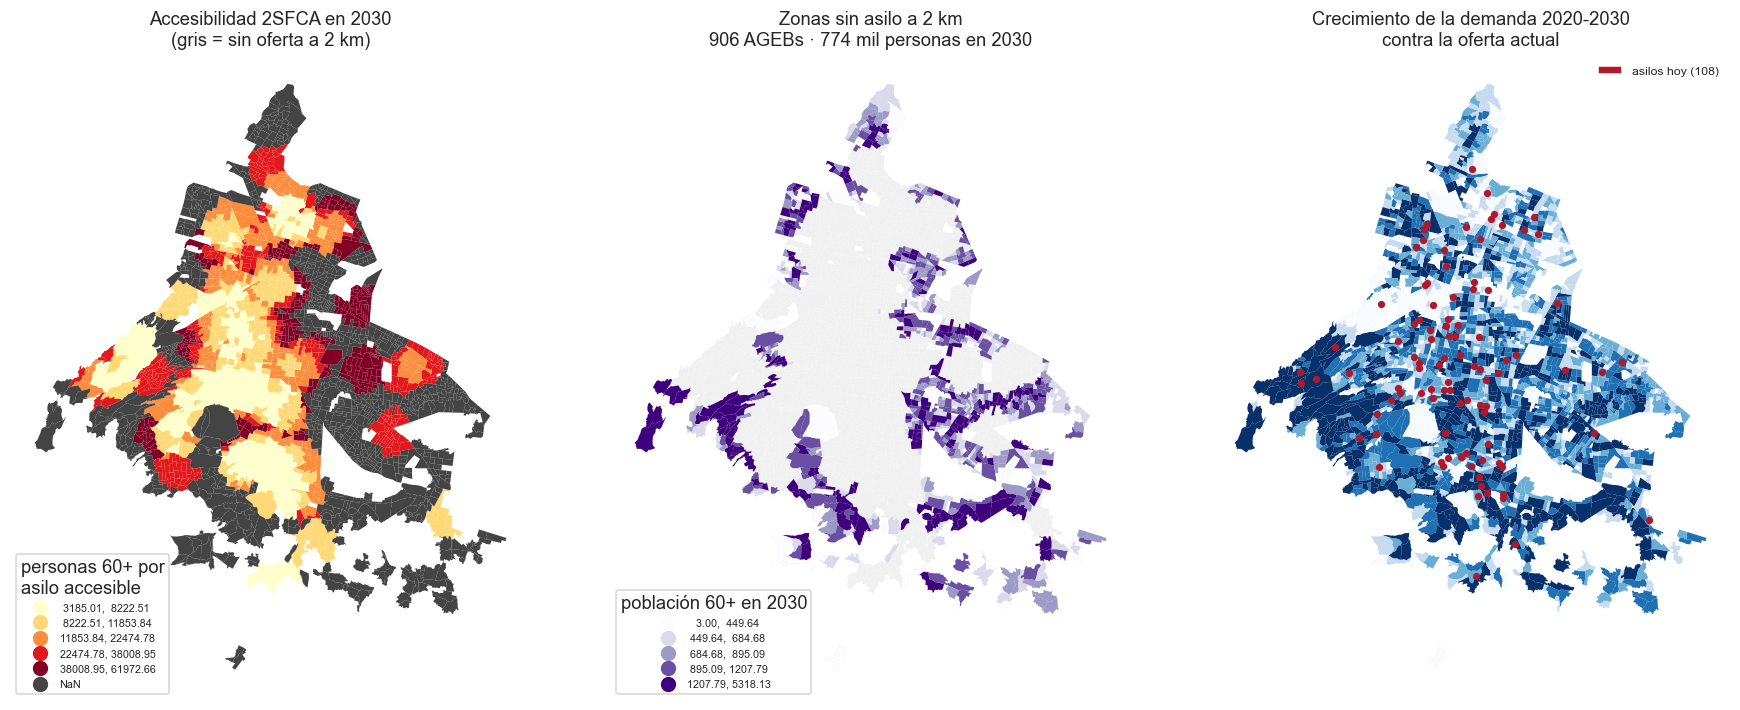

In [32]:
from matplotlib.patches import Patch
fig, ax = plt.subplots(1, 3, figsize=(16.5, 6.4))

acc.plot(column="pers_por_asilo", scheme="quantiles", k=5, cmap="YlOrRd", ax=ax[0], legend=True,
         edgecolor="none", missing_kwds={"color": "#444444"},
         legend_kwds={"fontsize": 7, "loc": "lower left", "title": "personas 60+ por\nasilo accesible"})
ax[0].set_title("Accesibilidad 2SFCA en 2030\n(gris = sin oferta a 2 km)")

acc.plot(color="#F0F0F0", edgecolor="white", linewidth=.05, ax=ax[1])
acc[sin].plot(column="p60_2030", scheme="quantiles", k=5, cmap="Purples", ax=ax[1], legend=True,
              edgecolor="none", legend_kwds={"fontsize": 7, "loc": "lower left",
                                             "title": "población 60+ en 2030"})
ax[1].set_title(f"Zonas sin asilo a 2 km\n{int(sin.sum()):,} AGEBs · "
                f"{acc.loc[sin,'p60_2030'].sum()/1000:.0f} mil personas en 2030")

acc["crecimiento"] = acc.p60_2030 - acc.p60_2020
acc.plot(column="crecimiento", scheme="quantiles", k=5, cmap="Blues", ax=ax[2], legend=True,
         edgecolor="none", legend_kwds={"fontsize": 7, "loc": "lower left",
                                        "title": "nuevas personas 60+\n2020→2030"})
oferta.centroid.plot(ax=ax[2], color="#B2182B", markersize=14)
ax[2].legend(handles=[Patch(facecolor="#B2182B", label=f"asilos hoy ({int(acc.asilos.sum())})")],
             loc="upper right", frameon=False, fontsize=8)
ax[2].set_title("Crecimiento de la demanda 2020-2030\ncontra la oferta actual")
for a_ in ax: a_.set_axis_off()
plt.tight_layout(); plt.savefig(FIG/"14_brecha_territorial.png", dpi=150, bbox_inches="tight")
plt.show()

### 11.1 Lo que muestran los mapas

**38% de los AGEBs no tienen ningún asilo dentro de 2 km**, y ahí vivirán unas 774 mil personas de 60 y
más en 2030 — el 36% de la ciudad. Hoy son 516 mil, así que la población descubierta crece 50% en la
década aunque no cierre ni abra un solo asilo.

Entre las zonas que sí tienen cobertura, la saturación va de unas 6,600 personas por asilo accesible en
el decil mejor atendido a 42,900 en el peor: **una desigualdad de 6.5 veces**.

El contraste por alcaldía es el hallazgo central del análisis territorial. **Benito Juárez llegará a
2030 con 114 mil adultos mayores y ni una sola persona a más de 2 km de un asilo. Iztapalapa tendrá
394 mil y 230 mil de ellos sin cobertura.** Milpa Alta queda al 100% descubierta, con una mediana de
5.6 km al asilo más cercano.

El tercer mapa resume el problema de un vistazo: los puntos rojos (oferta actual) se apiñan en el
centro-poniente, mientras el azul oscuro (crecimiento de la demanda) se concentra en la periferia sur y
oriente. **La oferta está donde estuvo la demanda, no donde va a estar.**

La tabla de zonas prioritarias es el producto directamente accionable: AGEBs ordenados por población
proyectada de 60+ sin asilo cercano, con su distancia al más próximo. La lista completa, con las 2,396
unidades y sus métricas de accesibilidad, queda en `brecha_2030.csv`.

## 12. Conclusiones y limitaciones

**Lo que se sostiene:**

1. La población de 60+ creció 48% en una década y crecerá 39-52% más hacia 2030, concentrando el
   crecimiento en la periferia sur y poniente (Tlalpan, Xochimilco, Cuajimalpa, Tláhuac, Milpa Alta).
2. El share de cada AGEB dentro de su alcaldía es extraordinariamente estable (Spearman 0.97 en una
   década), lo que hace del método de razón anclado a CONAPO una base sólida.
3. Encoger la tasa de cada AGEB hacia la de su alcaldía gana en backtest contra todas las alternativas.
4. La elasticidad oferta-población ronda 1 sin controles y 0.55 controlando área y alcaldía, y es
   robusta a 150+ formas distintas de agrupar los AGEBs.
5. Hay heterogeneidad real entre alcaldías más allá de población y área (`sigma_alpha` claramente > 0),
   y va en dirección socioeconómica: las alcaldías de mayor ingreso concentran la oferta.

**Limitaciones que conviene tener presentes:**

- **La enfermería a domicilio no se modeló**, y no debe modelarse con estos datos: 12 establecimientos,
  autocorrelación espacial nula, ninguna agrupación la rescata. Además, un servicio *a domicilio* no
  atiende al AGEB donde está registrado sino a un radio, así que la unidad de análisis es incorrecta
  de origen.
- **La serie temporal del DENUE es sospechosa** en enfermería (17 → 26 → 12). Hay que verificar los
  criterios de extracción de cada corte antes de darle interpretación sustantiva.
- **2015 es una estimación de encuesta**, no un censo. Su error de muestreo contamina las tasas de
  crecimiento por quinquenio.
- **Faltan covariables socioeconómicas.** El patrón por alcaldía apunta con fuerza a que el ingreso
  explica la ubicación de la oferta, pero sin el índice de marginación por AGEB es una hipótesis, no
  un resultado.
- **Las proyecciones no están ancladas a CONAPO.** Se usan tasas observadas como sustituto; la versión
  final debería usar las proyecciones oficiales para los totales por alcaldía.
- **El modelo proyecta comportamiento, no necesidad.** Es "cuántos habrá si nada cambia", no "cuántos
  se necesitan".

**Siguientes pasos naturales:** incorporar marginación o nivel socioeconómico por AGEB, anclar a
CONAPO, y —para el análisis de accesibilidad real— pasar a un modelo de áreas de captación (2SFCA)
con tiempos de traslado, que es la forma correcta de medir cobertura de un servicio que la gente
alcanza desplazándose.